In [1]:
# ==============================================================================
# CELL 1 — INSTALL & IMPORTS
# ==============================================================================
# !pip install librosa soundfile scikit-learn tqdm -q

import os, glob, random, pickle
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
from tqdm import tqdm
import matplotlib.pyplot as plt

# ==============================================================================
# CELL 2 — SHARED CONSTANTS
# ==============================================================================

SWARAS         = ['sa', 're', 'ga', 'ma', 'pa', 'dha', 'ni']
SR             = 22050
N_MELS         = 64
HOP_LENGTH     = 512
N_FFT          = 2048
FIXED_FRAMES   = 128          # ~3 s padded/truncated for classifier input
DATA_DIR       = "/content/drive/MyDrive/recording for paper"
DEVICE         = "cuda" if torch.cuda.is_available() else "cpu"


In [2]:
# ==============================================================================
# CELL 3 — SHARED FEATURE EXTRACTOR
# ==============================================================================

def get_log_mel(audio, fixed_frames=FIXED_FRAMES):
    """Returns log-mel spectrogram [n_mels, fixed_frames]."""
    mel   = librosa.feature.melspectrogram(y=audio, sr=SR, n_fft=N_FFT,
                                           hop_length=HOP_LENGTH, n_mels=N_MELS)
    lmel  = librosa.power_to_db(mel, ref=np.max)          # [n_mels, T]
    if lmel.shape[1] < fixed_frames:
        lmel = np.pad(lmel, ((0, 0), (0, fixed_frames - lmel.shape[1])), mode='constant')
    else:
        lmel = lmel[:, :fixed_frames]
    return lmel                                            # [n_mels, fixed_frames]

def get_rfc_features(lmel):
    """Flat 192-dim feature vector for RFC."""
    return np.concatenate([lmel.mean(1), lmel.std(1), lmel.max(1)])

In [3]:
# ==============================================================================
# CELL 4 — DATASET LOADER  (isolated swaras)
# ==============================================================================

class SwaraDataset(Dataset):
    def __init__(self, data_dir, swaras, label_encoder=None):
        self.X, self.y, self.rfc_X = [], [], []

        files, raw_labels = [], []
        for s in swaras:
            for f in glob.glob(os.path.join(data_dir, s, "*.wav")) + \
                     glob.glob(os.path.join(data_dir, s, "*.WAV")):
                files.append(f)
                raw_labels.append(s)

        if label_encoder is None:
            self.le = LabelEncoder()
            self.le.fit(swaras)
        else:
            self.le = label_encoder

        for f, lbl in tqdm(zip(files, raw_labels), total=len(files), desc="Loading"):
            try:
                y_wav, _ = librosa.load(f, sr=SR)
                lmel     = get_log_mel(y_wav)
                self.X.append(lmel)
                self.rfc_X.append(get_rfc_features(lmel))
                self.y.append(self.le.transform([lbl])[0])
            except Exception as e:
                print(f"  Skip {f}: {e}")

    def __len__(self):  return len(self.X)
    def __getitem__(self, idx):
        x = torch.tensor(self.X[idx], dtype=torch.float32).unsqueeze(0)  # [1, n_mels, T]
        y = torch.tensor(self.y[idx], dtype=torch.long)
        return x, y


In [4]:
# ==============================================================================
# CELL 5 — CNN + ATTENTION MODEL
# ==============================================================================

class TemporalAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.w = nn.Linear(dim, 1)

    def forward(self, x):               # x: [B, T, dim]
        a = torch.softmax(self.w(x), dim=1)   # [B, T, 1]
        return (x * a).sum(dim=1)             # [B, dim]

class CNNAttentionClassifier(nn.Module):
    def __init__(self, n_mels=N_MELS, num_classes=7):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d((2, 2)),                              # → [32, 32, 64]
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d((2, 2)),                              # → [64, 16, 32]
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, None)),                   # → [128, 1, T']
        )
        self.attn       = TemporalAttention(128)
        self.classifier = nn.Sequential(
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):               # x: [B, 1, n_mels, T]
        out = self.cnn(x)               # [B, 128, 1, T']
        out = out.squeeze(2).permute(0, 2, 1)   # [B, T', 128]
        out = self.attn(out)            # [B, 128]
        return self.classifier(out)     # [B, num_classes]

In [5]:
# ==============================================================================
# CELL 6 — TRAIN BOTH CLASSIFIERS
# ==============================================================================

def train_classifiers(data_dir=DATA_DIR, epochs=20, batch_size=16, lr=1e-3):
    dataset = SwaraDataset(data_dir, SWARAS)
    le      = dataset.le

    # ── Train / Val split (80/20) ──────────────────────────────────────────
    n       = len(dataset)
    idx     = list(range(n))
    random.shuffle(idx)
    split   = int(0.8 * n)
    tr_idx, va_idx = idx[:split], idx[split:]

    tr_set  = torch.utils.data.Subset(dataset, tr_idx)
    va_set  = torch.utils.data.Subset(dataset, va_idx)
    tr_load = DataLoader(tr_set, batch_size=batch_size, shuffle=True)
    va_load = DataLoader(va_set, batch_size=batch_size)

    # ─────────────────────────────────────────────────────────────────────
    # A) CNN + ATTENTION
    # ─────────────────────────────────────────────────────────────────────
    cnn_model = CNNAttentionClassifier(num_classes=len(SWARAS)).to(DEVICE)
    optimizer = torch.optim.Adam(cnn_model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    print("── Training CNN+Attention ──")
    for epoch in range(epochs):
        cnn_model.train()
        total_loss = 0
        for xb, yb in tr_load:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(cnn_model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        # Validation accuracy
        cnn_model.eval()
        correct = total = 0
        with torch.no_grad():
            for xb, yb in va_load:
                preds = cnn_model(xb.to(DEVICE)).argmax(1).cpu()
                correct += (preds == yb).sum().item()
                total   += len(yb)
        print(f"  Epoch {epoch+1:02d}/{epochs}  loss={total_loss/len(tr_load):.4f}  val_acc={correct/total:.3f}")

    torch.save(cnn_model.state_dict(), "swara_cnn_attention.pth")
    print("  Saved → swara_cnn_attention.pth\n")

    # ─────────────────────────────────────────────────────────────────────
    # B) RANDOM FOREST CLASSIFIER
    # ─────────────────────────────────────────────────────────────────────
    print("── Training Random Forest ──")
    rfc_X = np.array(dataset.rfc_X)
    rfc_y = np.array(dataset.y)

    tr_Xr, va_Xr = rfc_X[tr_idx], rfc_X[va_idx]
    tr_yr, va_yr = rfc_y[tr_idx], rfc_y[va_idx]

    rfc = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)
    rfc.fit(tr_Xr, tr_yr)
    print(f"  RFC val_acc: {accuracy_score(va_yr, rfc.predict(va_Xr)):.3f}")
    print(classification_report(va_yr, rfc.predict(va_Xr), target_names=le.classes_))

    with open("swara_rfc.pkl", "wb") as f:
        pickle.dump(rfc, f)
    with open("swara_label_encoder.pkl", "wb") as f:
        pickle.dump(le, f)
    print("  Saved → swara_rfc.pkl\n")

    return cnn_model, rfc, le

# ── Run training ──────────────────────────────────────────────────────────────
cnn_model, rfc_model, label_enc = train_classifiers()

Loading: 100%|██████████| 748/748 [06:03<00:00,  2.06it/s]


── Training CNN+Attention ──
  Epoch 01/20  loss=1.9371  val_acc=0.227
  Epoch 02/20  loss=1.8668  val_acc=0.313
  Epoch 03/20  loss=1.6562  val_acc=0.460
  Epoch 04/20  loss=1.3625  val_acc=0.620
  Epoch 05/20  loss=1.2470  val_acc=0.540
  Epoch 06/20  loss=1.0909  val_acc=0.560
  Epoch 07/20  loss=0.9580  val_acc=0.740
  Epoch 08/20  loss=0.8604  val_acc=0.787
  Epoch 09/20  loss=0.7753  val_acc=0.653
  Epoch 10/20  loss=0.7852  val_acc=0.740
  Epoch 11/20  loss=0.7465  val_acc=0.813
  Epoch 12/20  loss=0.6403  val_acc=0.847
  Epoch 13/20  loss=0.5304  val_acc=0.880
  Epoch 14/20  loss=0.4918  val_acc=0.807
  Epoch 15/20  loss=0.4702  val_acc=0.740
  Epoch 16/20  loss=0.4525  val_acc=0.873
  Epoch 17/20  loss=0.3913  val_acc=0.593
  Epoch 18/20  loss=0.4327  val_acc=0.793
  Epoch 19/20  loss=0.4000  val_acc=0.860
  Epoch 20/20  loss=0.2922  val_acc=0.947
  Saved → swara_cnn_attention.pth

── Training Random Forest ──
  RFC val_acc: 0.927
              precision    recall  f1-score   

In [9]:
import os
import glob
import pandas as pd
import numpy as np
import librosa
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt

# ==============================================================================
# 1. AUDIO DATASET WITH FRAME-LEVEL ALIGNMENT
# ==============================================================================
class FluteSegmentationDataset(Dataset):
    def __init__(self, csv_path, audio_dir, sr=22050, n_mels=64, hop_length=512, n_fft=2048, max_len_frames=500):
        self.df_master = pd.read_csv(csv_path)
        self.audio_dir = audio_dir
        self.sr = sr
        self.n_mels = n_mels
        self.hop_length = hop_length
        self.n_fft = n_fft
        self.max_len_frames = max_len_frames

        # Get unique melody files to iterate over
        self.melody_files = self.df_master['melody_file'].unique()

    def __len__(self):
        return len(self.melody_files)

    def __getitem__(self, idx):
        filename = self.melody_files[idx]
        audio_path = os.path.join(self.audio_dir, filename)

        # 1. Load Audio and Extract Log-Mel Spectrogram
        y, _ = librosa.load(audio_path, sr=self.sr)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=self.sr, n_fft=self.n_fft,
                                                 hop_length=self.hop_length, n_mels=self.n_mels)
        log_mel = librosa.power_to_db(mel_spec, ref=np.max)

        # Shape translation: [n_mels, time_frames] -> [time_frames, n_mels]
        log_mel = log_mel.T
        num_frames = log_mel.shape[0]

        # 2. Build Target Frame Array (0: Non-boundary, 1: Boundary Transition)
        target = np.zeros(num_frames, dtype=np.float32)

        # Calculate time-duration of a single frame
        frame_duration = self.hop_length / self.sr

        # Filter all note events belonging strictly to this audio track
        tracks_notes = self.df_master[self.df_master['melody_file'] == filename].sort_values('note_sequence_idx')

        # Mark boundaries at note transitions (start of notes except the absolute phrase start)
        for _, row in tracks_notes.iterrows():
            if row['note_sequence_idx'] > 0: # Avoid marking the very beginning of the audio track
                boundary_time = row['start_time']
                center_frame = int(round(boundary_time / frame_duration))

                # Apply a target window of 3 frames tolerance centered at boundary
                if center_frame < num_frames:
                    start_f = max(0, center_frame - 1)
                    end_f = min(num_frames, center_frame + 2)
                    target[start_f:end_f] = 1.0

        # 3. Handle Variable Length Padding / Truncation for Batch Processing
        if num_frames < self.max_len_frames:
            # Pad Log-Mel and Targets with zeros
            pad_width = self.max_len_frames - num_frames
            log_mel = np.pad(log_mel, ((0, pad_width), (0, 0)), mode='constant')
            target = np.pad(target, (0, pad_width), mode='constant')
            mask = np.concatenate([np.ones(num_frames), np.zeros(pad_width)]).astype(np.float32)
        else:
            # Truncate
            log_mel = log_mel[:self.max_len_frames, :]
            target = target[:self.max_len_frames]
            mask = np.ones(self.max_len_frames, dtype=np.float32)

        # PyTorch Tensor casting (Add channel dimension to Mel Spec for 2D Convolution)
        # Expected CNN Input Shape: [Batch, Channel=1, Time, Frequency]
        return (
            torch.tensor(log_mel, dtype=torch.float32).unsqueeze(0),
            torch.tensor(target, dtype=torch.float32),
            torch.tensor(mask, dtype=torch.float32)
        )

# ==============================================================================
# 2. CRNN ARCHITECTURE SETUP (CNN -> BiLSTM -> Frame Classifier)
# ==============================================================================
class FluteSegmentationCRNN(nn.Module):
    def __init__(self, n_mels=64, hidden_size=128, num_layers=2):
        super(FluteSegmentationCRNN, self).__init__()

        # Small Front-End CNN to compress frequency feature space
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=(3, 3), padding=(1, 1)),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(1, 2)), # Keeps time frames intact, cuts frequency features in half

            nn.Conv2d(16, 32, kernel_size=(3, 3), padding=(1, 1)),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(1, 2))  # Cuts frequency features down again
        )

        # Determine flattened size out of CNN pooling layers
        # 64 mels divided by 4 due to two MaxPool layers along axis-2 = 16 features * 32 channels
        rnn_input_size = 32 * (n_mels // 4)

        # Recurrent Back-End for modeling contextual forward/backward transitions
        self.bilstm = nn.LSTM(input_size=rnn_input_size,
                              hidden_size=hidden_size,
                              num_layers=num_layers,
                              batch_first=True,
                              bidirectional=True)

        # Final classification projection layer mapping to binary output probability
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        # x shape: [Batch, Channel=1, Time, Freq]
        b, c, t, f = x.size()

        # Run spatial convolutions
        out = self.cnn(x) # Shape: [Batch, Channels=32, Time, Freq_reduced]

        # Rearrange feature representation for Recurrent Processing
        out = out.permute(0, 2, 1, 3).contiguous() # Shape: [Batch, Time, Channels, Freq_reduced]
        out = out.view(b, t, -1) # Flatten spatial parameters: [Batch, Time, Channels * Freq_reduced]

        # Run Sequence Model
        lstm_out, _ = self.bilstm(out) # Shape: [Batch, Time, Hidden_Size * 2]

        # Project down to binary probabilities per frame step
        predictions = self.classifier(lstm_out).squeeze(-1) # Shape: [Batch, Time]
        return predictions

# ==============================================================================
# 3. TRAINING ROUTINE
# ==============================================================================
def train_model(model, dataloader, epochs=15, lr=0.001, device="cuda"):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCELoss(reduction='none') # Compute element-wise loss to allow zero-mask padding ignore

    print(f"Moving model to {device} context. Beginning training loops...")
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for batch_specs, batch_targets, batch_masks in dataloader:
            batch_specs = batch_specs.to(device)
            batch_targets = batch_targets.to(device)
            batch_masks = batch_masks.to(device)

            optimizer.zero_grad()

            predictions = model(batch_specs)

            # Apply element-wise loss along with padding tracking masks
            loss = criterion(predictions, batch_targets)
            masked_loss = (loss * batch_masks).sum() / batch_masks.sum()

            masked_loss.backward()
            optimizer.step()

            total_loss += masked_loss.item()

        print(f"Epoch [{epoch+1}/{epochs}] Completed -> Loss: {total_loss/len(dataloader):.4f}")

    print("Training process finalized successfully.")
    return model

# ==============================================================================
# 4. INSTANTIATION RUNTIME ENGINE
# ==============================================================================
if __name__ == "__main__":
    CSV_PATH = "/content/drive/MyDrive/train_synthetic_melody/all_melodies_metadata.csv"
    AUDIO_DIR = "/content/drive/MyDrive/train_synthetic_melody"
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    if os.path.exists(CSV_PATH):
        # Setup Data Pipelines
        dataset = FluteSegmentationDataset(CSV_PATH, AUDIO_DIR)
        loader = DataLoader(dataset, batch_size=16, shuffle=True)

        # Compile Model Structure
        model = FluteSegmentationCRNN(n_mels=64)

        # Run Optimization Process
        trained_model = train_model(model, loader, epochs=15, device=DEVICE)

        # Save structural checkpoint state dictionary
        torch.save(trained_model.state_dict(), "flute_segmenter_crnn.pth")
    else:
        print(f"Initialization Failed: Generate your synthetic data assets into '{AUDIO_DIR}' first before running training execution.")

Moving model to cuda context. Beginning training loops...
Epoch [1/15] Completed -> Loss: 0.2236
Epoch [2/15] Completed -> Loss: 0.0706
Epoch [3/15] Completed -> Loss: 0.0373
Epoch [4/15] Completed -> Loss: 0.0269
Epoch [5/15] Completed -> Loss: 0.0219
Epoch [6/15] Completed -> Loss: 0.0186
Epoch [7/15] Completed -> Loss: 0.0157
Epoch [8/15] Completed -> Loss: 0.0133
Epoch [9/15] Completed -> Loss: 0.0133
Epoch [10/15] Completed -> Loss: 0.0100
Epoch [11/15] Completed -> Loss: 0.0094
Epoch [12/15] Completed -> Loss: 0.0080
Epoch [13/15] Completed -> Loss: 0.0074
Epoch [14/15] Completed -> Loss: 0.0067
Epoch [15/15] Completed -> Loss: 0.0070
Training process finalized successfully.


In [10]:
# ==============================================================================
# CELL 8 — FULL INFERENCE PIPELINE
# ==============================================================================

def classify_segment(audio_segment, cnn_model, rfc_model, label_enc):
    """Returns (cnn_label, rfc_label) for one audio chunk."""
    lmel     = get_log_mel(audio_segment)
    rfc_feat = get_rfc_features(lmel)

    # CNN + Attention
    cnn_model.eval()
    with torch.no_grad():
        x   = torch.tensor(lmel, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(DEVICE)
        out = cnn_model(x)
        cnn_idx = out.argmax(1).item()
    cnn_label = label_enc.inverse_transform([cnn_idx])[0]

    # RFC
    rfc_pred  = rfc_model.predict([rfc_feat])[0]
    rfc_label = label_enc.inverse_transform([rfc_pred])[0]

    return cnn_label, rfc_label


def run_pipeline(
    audio_path,
    seg_model_path    = "flute_segmenter_crnn.pth",
    cnn_model_path    = "swara_cnn_attention.pth",
    rfc_model_path    = "swara_rfc.pkl",
    le_path           = "swara_label_encoder.pkl",
    threshold         = 0.5,
    min_gap_sec       = 0.15,   # suppress boundary triggers closer than this
    min_seg_dur_sec   = 0.20,   # drop any segment shorter than this
    end_margin_sec    = 0.30,   # ignore last boundary if ≤ this from audio end
):
    # ── Load models ──────────────────────────────────────────────────────
    seg_model = FluteSegmentationCRNN()
    seg_model.load_state_dict(torch.load(seg_model_path, map_location=DEVICE))
    seg_model.to(DEVICE).eval()

    with open(rfc_model_path,  "rb") as f: rfc  = pickle.load(f)
    with open(le_path,         "rb") as f: le   = pickle.load(f)
    cnn = CNNAttentionClassifier(num_classes=len(SWARAS)).to(DEVICE)
    cnn.load_state_dict(torch.load(cnn_model_path, map_location=DEVICE))
    cnn.eval()

    # ── Load & featurise audio ────────────────────────────────────────────
    y, _    = librosa.load(audio_path, sr=SR)
    duration = len(y) / SR

    mel_spec   = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT,
                                                hop_length=HOP_LENGTH, n_mels=N_MELS)
    log_mel    = librosa.power_to_db(mel_spec, ref=np.max)
    input_t    = torch.tensor(log_mel.T, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(DEVICE)

    # ── Segmentation forward pass ─────────────────────────────────────────
    with torch.no_grad():
        preds = seg_model(input_t).squeeze(0).cpu().numpy()

    time_axis = np.arange(len(preds)) * (HOP_LENGTH / SR)

    # ── Collect raw boundary times ────────────────────────────────────────
    raw_times = time_axis[preds > threshold]

    # ── Suppress clusters (keep first of each ≥ min_gap_sec group) ───────
    boundaries = []
    if len(raw_times) > 0:
        last = raw_times[0]
        boundaries.append(last)
        for t in raw_times[1:]:
            if t - last > min_gap_sec:
                boundaries.append(t)
                last = t

    # ── EDGE CASE: drop final boundary if it is near the end ─────────────
    if boundaries and (duration - boundaries[-1]) <= end_margin_sec:
        print(f"  [Edge] Dropping last boundary at {boundaries[-1]:.3f}s "
              f"(only {duration - boundaries[-1]:.3f}s from end)")
        boundaries = boundaries[:-1]

    print(f"\nFinal boundaries ({len(boundaries)}): "
          + ", ".join(f"{b:.3f}s" for b in boundaries))

    # ── Build segment list: [0, b1, b2, …, end] ──────────────────────────
    cut_points = [0.0] + boundaries + [duration]
    segments   = []
    for i in range(len(cut_points) - 1):
        t_start = cut_points[i]
        t_end   = cut_points[i + 1]
        if t_end - t_start >= min_seg_dur_sec:   # drop too-short fragments
            segments.append((t_start, t_end))
        else:
            print(f"  [Edge] Dropping short segment [{t_start:.3f}–{t_end:.3f}]s "
                  f"({t_end - t_start:.3f}s < {min_seg_dur_sec}s)")

    print(f"Classifying {len(segments)} segments...\n")

    # ── Classify each segment ─────────────────────────────────────────────
    cnn_seq, rfc_seq = [], []
    for i, (t0, t1) in enumerate(segments):
        s0   = int(t0 * SR)
        s1   = int(t1 * SR)
        clip = y[s0:s1]
        c_lbl, r_lbl = classify_segment(clip, cnn, rfc, le)
        cnn_seq.append(c_lbl)
        rfc_seq.append(r_lbl)
        print(f"  Seg {i+1:02d}  [{t0:.3f}s – {t1:.3f}s]  "
              f"CNN={c_lbl}  RFC={r_lbl}")

    # ── Print melody sequences ────────────────────────────────────────────
    print("\n" + "="*50)
    print("CNN+Attention sequence: " + " → ".join(cnn_seq))
    print("RFC sequence:           " + " → ".join(rfc_seq))
    print("="*50)

    # ── Visualisation ─────────────────────────────────────────────────────
    fig, axes = plt.subplots(3, 1, figsize=(14, 10))

    # Spectrogram
    librosa.display.specshow(log_mel, sr=SR, hop_length=HOP_LENGTH,
                             x_axis='time', y_axis='mel',
                             cmap='magma', ax=axes[0])
    axes[0].set_title(f"Mel Spectrogram — {os.path.basename(audio_path)}")
    for t0, _ in segments:
        axes[0].axvline(t0, color='cyan', lw=1.2, alpha=0.8)

    # Boundary probability
    axes[1].plot(time_axis, preds, color='crimson', lw=1.5)
    axes[1].axhline(threshold, color='gray', ls='--', lw=1)
    for t0, _ in segments:
        axes[1].axvline(t0, color='darkgreen', ls='--', lw=1.2)
    axes[1].fill_between(time_axis, preds, where=(preds >= threshold),
                         color='red', alpha=0.25)
    axes[1].set_ylim(-0.05, 1.05)
    axes[1].set_xlim(0, duration)
    axes[1].set_title("Boundary Confidence")
    axes[1].set_ylabel("Probability")

    # Swara sequence strip
    axes[2].set_xlim(0, duration)
    axes[2].set_ylim(0, 1)
    cmap_colors = plt.cm.Set2(np.linspace(0, 1, len(SWARAS)))
    color_map   = {s: cmap_colors[i] for i, s in enumerate(SWARAS)}
    for i, ((t0, t1), lbl) in enumerate(zip(segments, cnn_seq)):
        axes[2].barh(0.5, t1 - t0, left=t0, height=0.6,
                     color=color_map.get(lbl, 'gray'), alpha=0.85, edgecolor='white')
        axes[2].text((t0 + t1) / 2, 0.5, lbl, ha='center', va='center',
                     fontsize=9, fontweight='bold', color='white')
    axes[2].set_title("CNN+Attention — Predicted Swara Sequence")
    axes[2].set_xlabel("Time (s)")
    axes[2].set_yticks([])

    plt.tight_layout()
    plt.savefig("pipeline_output.png", dpi=120)
    plt.show()

    return cnn_seq, rfc_seq, segments

Upload one or more test flute .wav files:


Saving test1.wav to test1 (2).wav
Saving test2.wav to test2 (1).wav
Saving test3.wav to test3 (1).wav
Saving test4.wav to test4 (1).wav
Saving test5.wav to test5 (1).wav
Saving test6.wav to test6.wav
Saving test7.wav to test7.wav
Saving test8.wav to test8.wav
Saving test9.wav to test9.wav
Saving test10.wav to test10.wav
Saving test11.wav to test11.wav
Saving test12.wav to test12.wav
Saving test13.wav to test13.wav
Saving test14.wav to test14.wav
Saving test15.wav to test15.wav
Saving test16.wav to test16.wav
Saving test17.wav to test17.wav
Saving test18.wav to test18.wav
Saving test19.wav to test19.wav

Processing: test1 (2).wav

Final boundaries (11): 1.184s, 2.090s, 3.088s, 3.576s, 4.017s, 5.016s, 7.500s, 7.964s, 8.963s, 9.938s, 11.006s
Classifying 12 segments...

  Seg 01  [0.000s – 1.184s]  CNN=sa  RFC=sa
  Seg 02  [1.184s – 2.090s]  CNN=re  RFC=re
  Seg 03  [2.090s – 3.088s]  CNN=sa  RFC=sa
  Seg 04  [3.088s – 3.576s]  CNN=re  RFC=re
  Seg 05  [3.576s – 4.017s]  CNN=ni  RFC=sa
  S

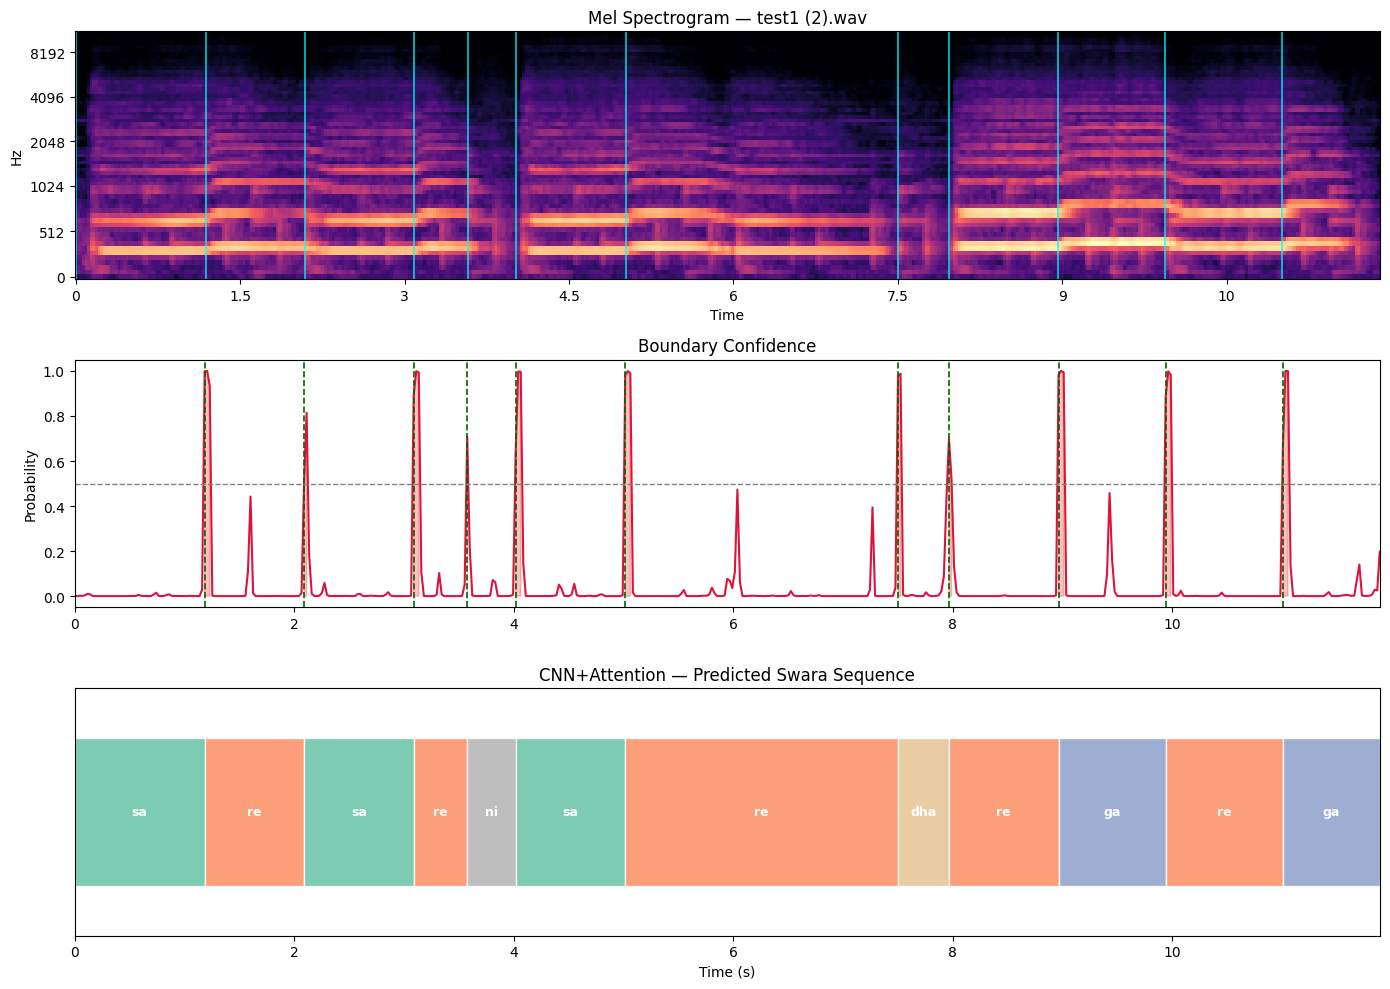


Processing: test2 (1).wav
  [Edge] Dropping last boundary at 3.111s (only 0.255s from end)

Final boundaries (6): 0.464s, 0.952s, 1.416s, 1.927s, 2.368s, 2.926s
Classifying 7 segments...

  Seg 01  [0.000s – 0.464s]  CNN=sa  RFC=sa
  Seg 02  [0.464s – 0.952s]  CNN=re  RFC=re
  Seg 03  [0.952s – 1.416s]  CNN=ni  RFC=ga
  Seg 04  [1.416s – 1.927s]  CNN=sa  RFC=sa
  Seg 05  [1.927s – 2.368s]  CNN=re  RFC=re
  Seg 06  [2.368s – 2.926s]  CNN=ga  RFC=ga
  Seg 07  [2.926s – 3.367s]  CNN=ma  RFC=ma

CNN+Attention sequence: sa → re → ni → sa → re → ga → ma
RFC sequence:           sa → re → ga → sa → re → ga → ma


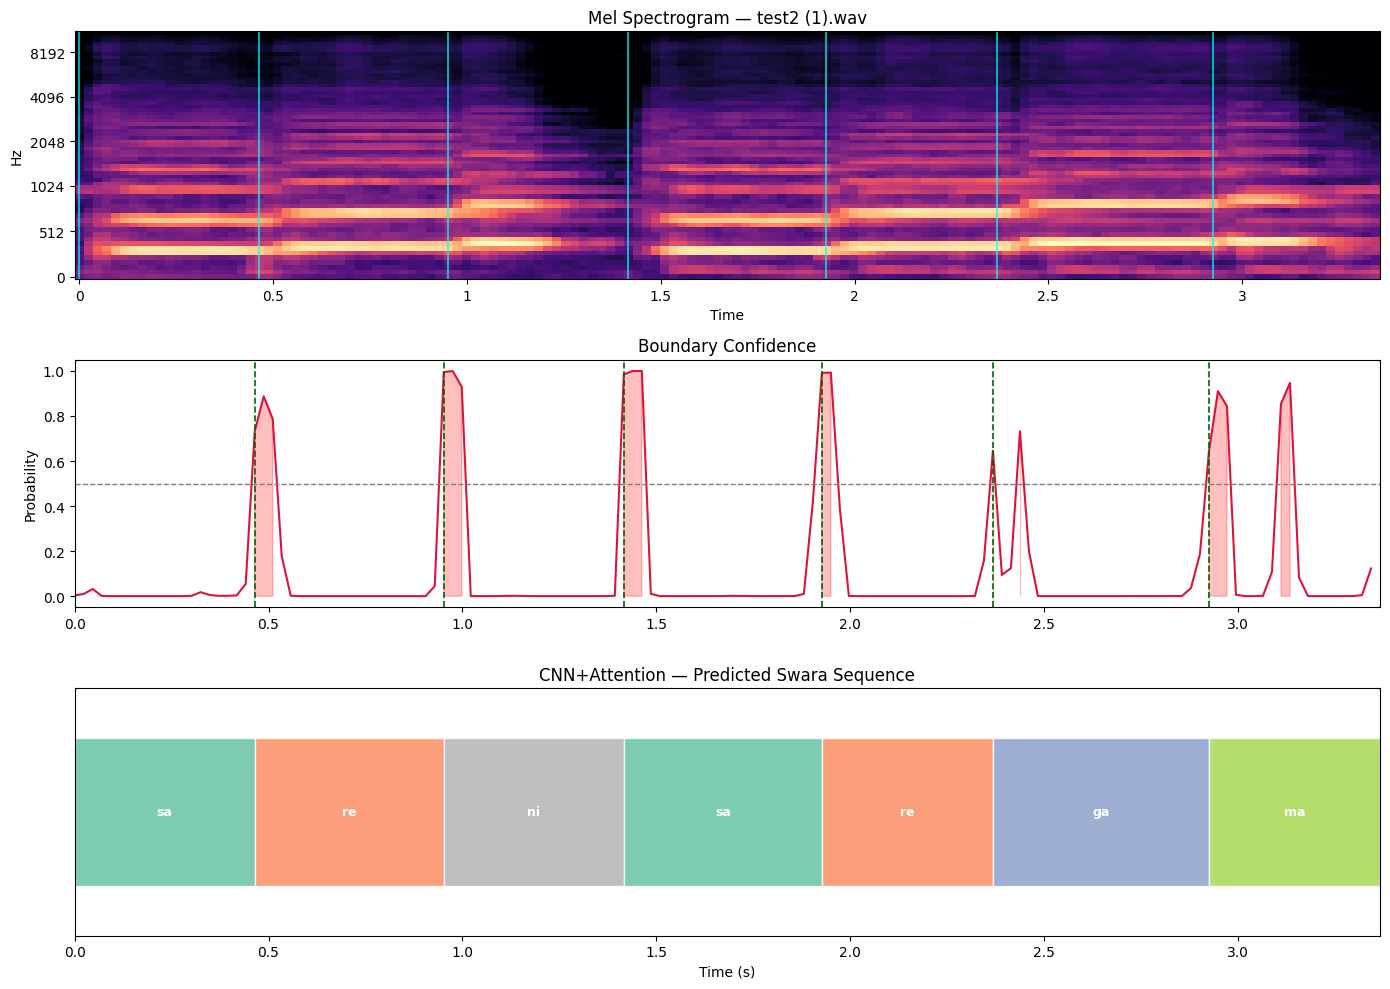


Processing: test3 (1).wav

Final boundaries (5): 0.488s, 0.929s, 1.950s, 2.415s, 2.879s
Classifying 6 segments...

  Seg 01  [0.000s – 0.488s]  CNN=re  RFC=re
  Seg 02  [0.488s – 0.929s]  CNN=ga  RFC=ga
  Seg 03  [0.929s – 1.950s]  CNN=re  RFC=dha
  Seg 04  [1.950s – 2.415s]  CNN=ga  RFC=ga
  Seg 05  [2.415s – 2.879s]  CNN=ma  RFC=ma
  Seg 06  [2.879s – 3.386s]  CNN=dha  RFC=pa

CNN+Attention sequence: re → ga → re → ga → ma → dha
RFC sequence:           re → ga → dha → ga → ma → pa


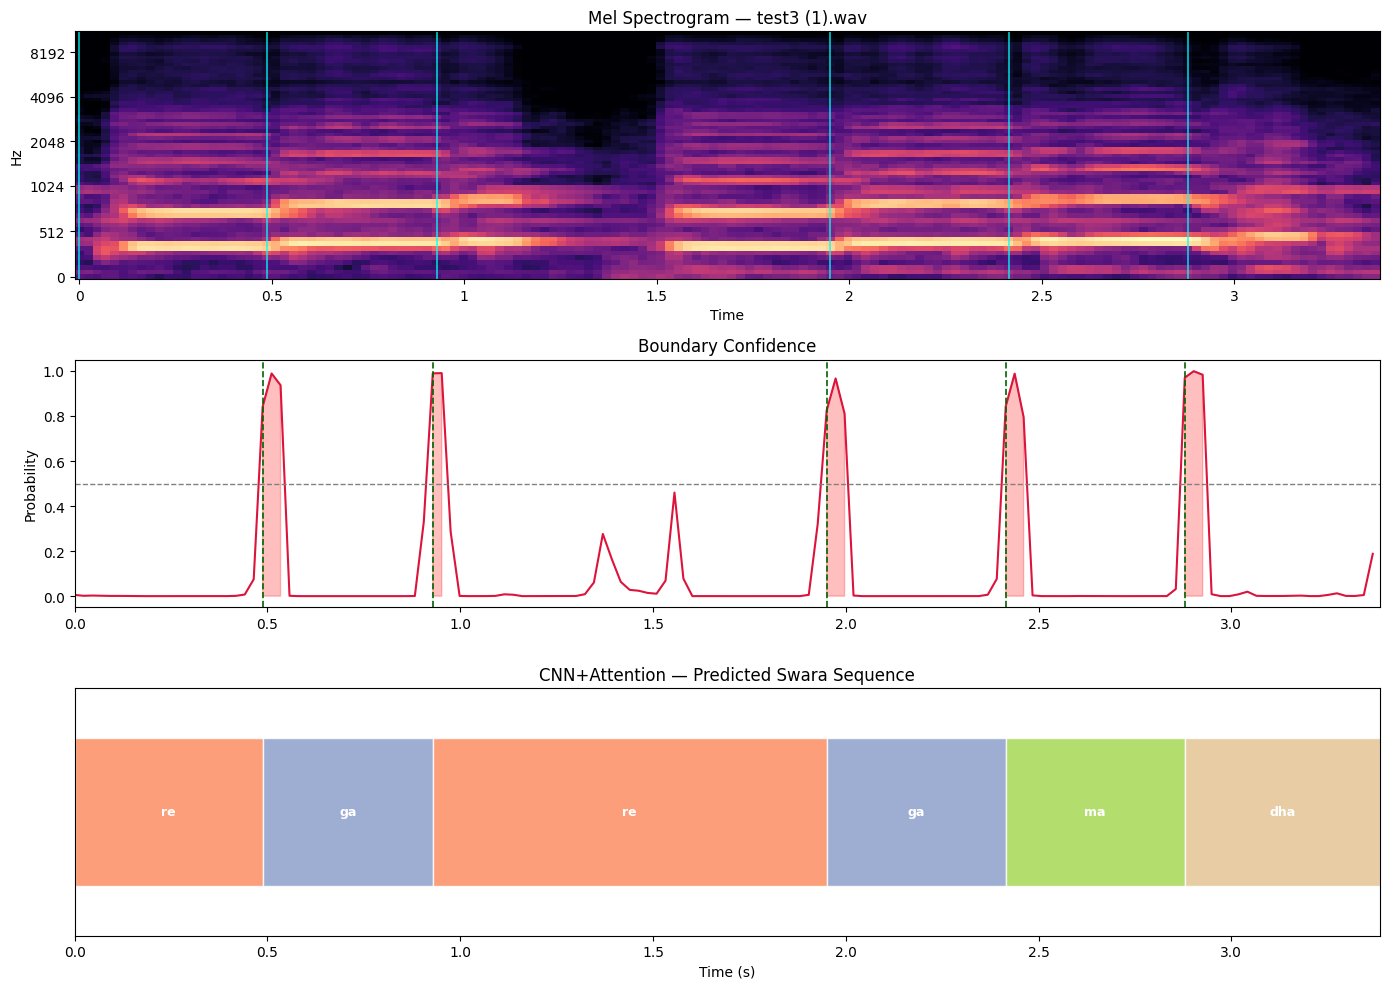


Processing: test4 (1).wav

Final boundaries (6): 0.511s, 0.998s, 1.579s, 1.950s, 2.461s, 2.926s
Classifying 7 segments...

  Seg 01  [0.000s – 0.511s]  CNN=ga  RFC=ga
  Seg 02  [0.511s – 0.998s]  CNN=ma  RFC=ma
  Seg 03  [0.998s – 1.579s]  CNN=pa  RFC=pa
  Seg 04  [1.579s – 1.950s]  CNN=ga  RFC=ma
  Seg 05  [1.950s – 2.461s]  CNN=ma  RFC=ma
  Seg 06  [2.461s – 2.926s]  CNN=pa  RFC=pa
  Seg 07  [2.926s – 3.437s]  CNN=dha  RFC=dha

CNN+Attention sequence: ga → ma → pa → ga → ma → pa → dha
RFC sequence:           ga → ma → pa → ma → ma → pa → dha


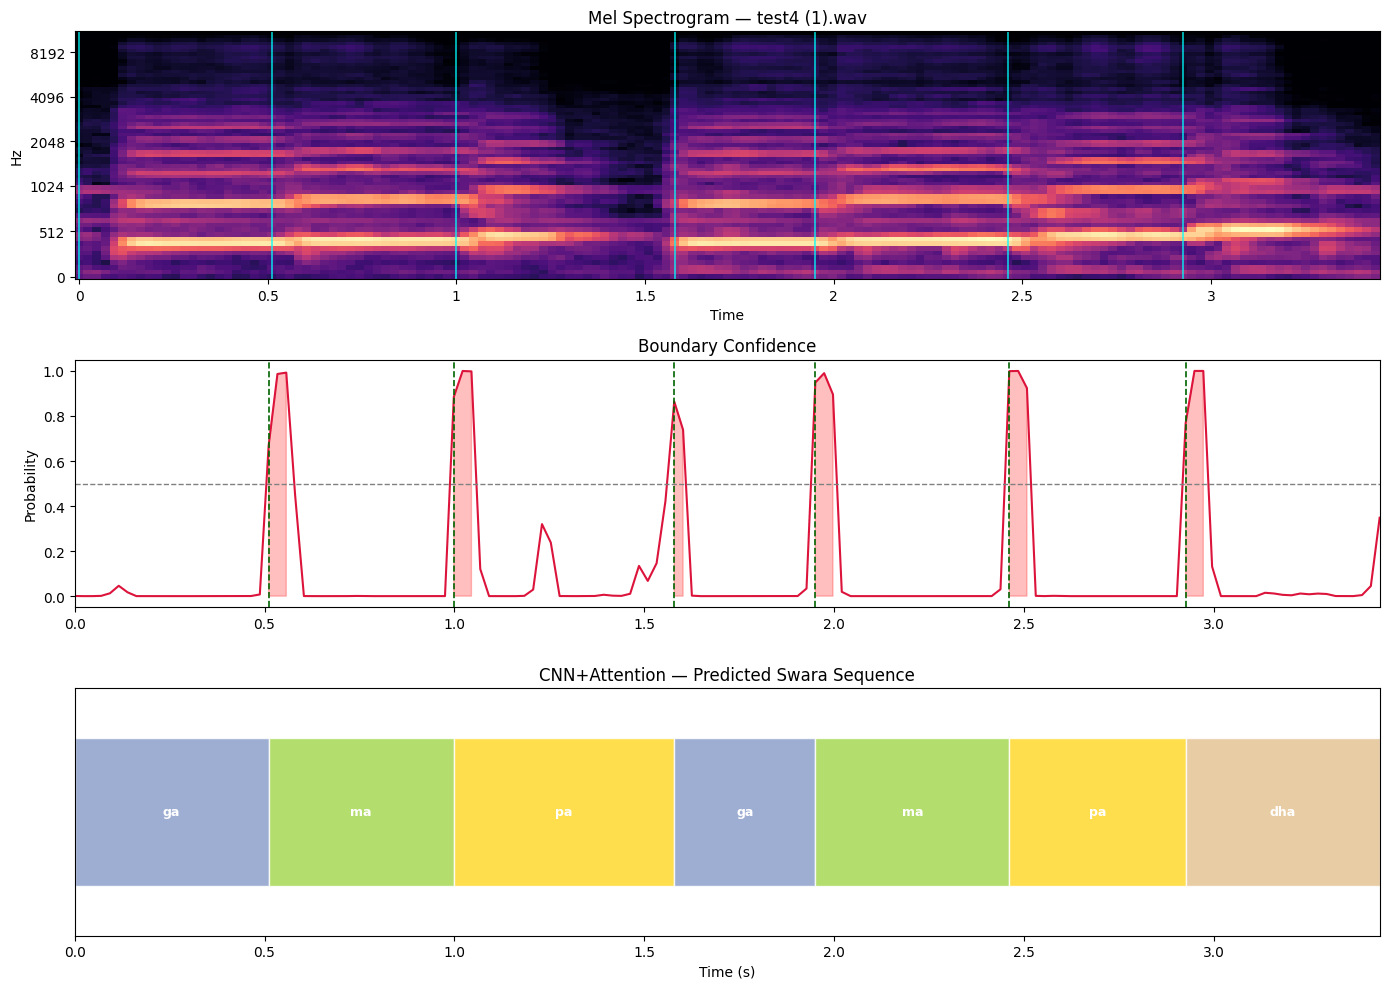


Processing: test5 (1).wav
  [Edge] Dropping last boundary at 3.204s (only 0.224s from end)

Final boundaries (7): 0.116s, 0.534s, 0.998s, 1.556s, 1.997s, 2.485s, 2.972s
  [Edge] Dropping short segment [0.000–0.116]s (0.116s < 0.2s)
Classifying 7 segments...

  Seg 01  [0.116s – 0.534s]  CNN=ma  RFC=ma
  Seg 02  [0.534s – 0.998s]  CNN=pa  RFC=pa
  Seg 03  [0.998s – 1.556s]  CNN=dha  RFC=dha
  Seg 04  [1.556s – 1.997s]  CNN=ma  RFC=ma
  Seg 05  [1.997s – 2.485s]  CNN=pa  RFC=pa
  Seg 06  [2.485s – 2.972s]  CNN=dha  RFC=dha
  Seg 07  [2.972s – 3.428s]  CNN=ni  RFC=ni

CNN+Attention sequence: ma → pa → dha → ma → pa → dha → ni
RFC sequence:           ma → pa → dha → ma → pa → dha → ni


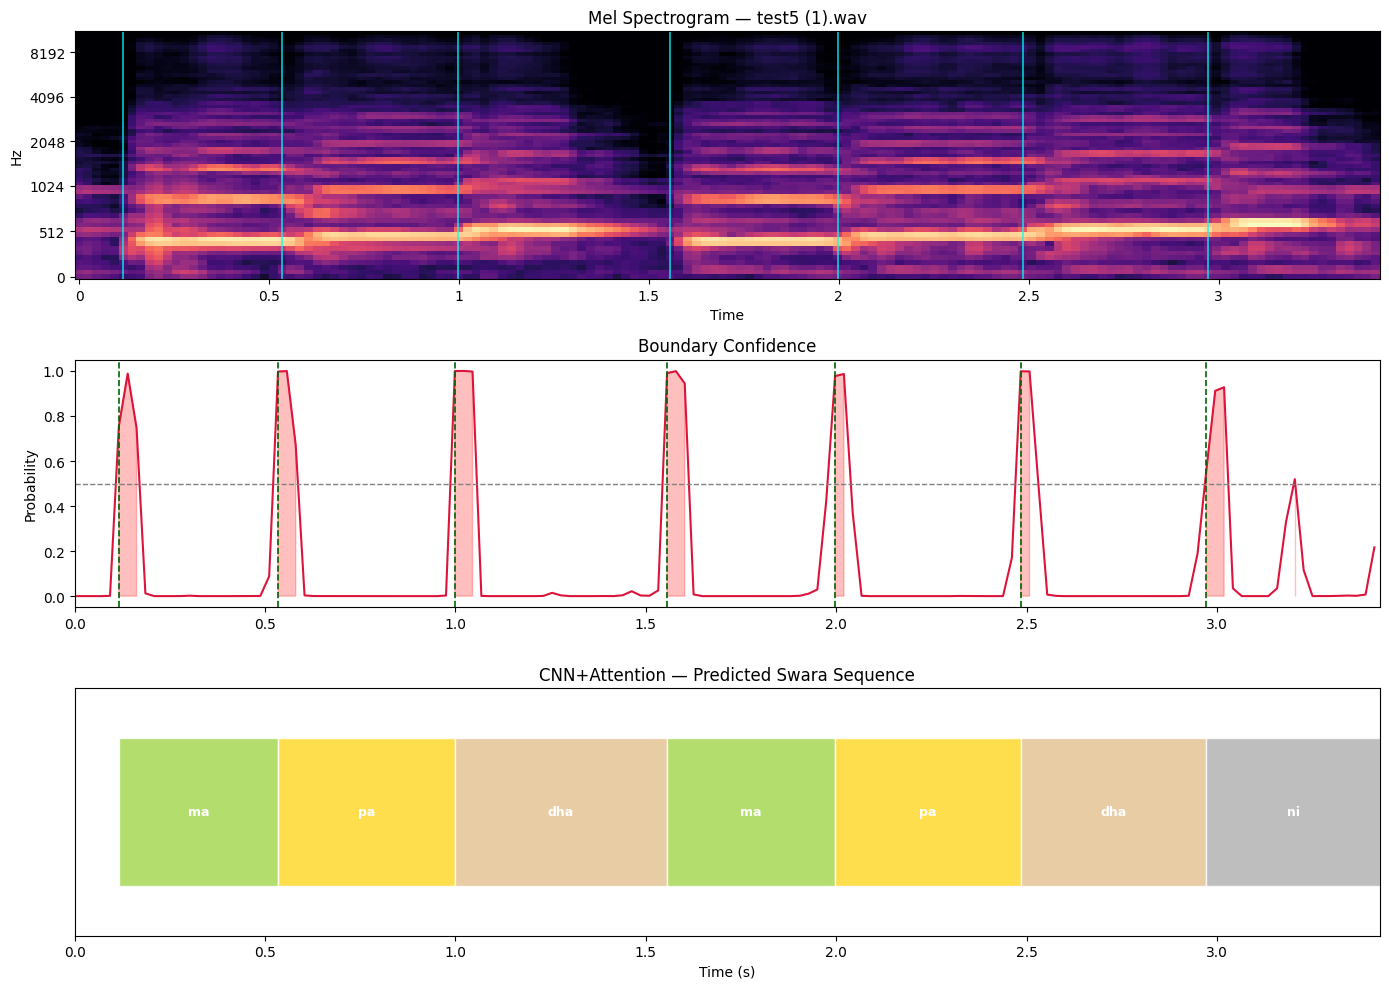


Processing: test6.wav
  [Edge] Dropping last boundary at 3.228s (only 0.229s from end)

Final boundaries (6): 0.488s, 1.022s, 1.509s, 1.997s, 2.461s, 2.926s
Classifying 7 segments...

  Seg 01  [0.000s – 0.488s]  CNN=pa  RFC=pa
  Seg 02  [0.488s – 1.022s]  CNN=dha  RFC=dha
  Seg 03  [1.022s – 1.509s]  CNN=ni  RFC=ni
  Seg 04  [1.509s – 1.997s]  CNN=pa  RFC=pa
  Seg 05  [1.997s – 2.461s]  CNN=dha  RFC=dha
  Seg 06  [2.461s – 2.926s]  CNN=ni  RFC=ni
  Seg 07  [2.926s – 3.456s]  CNN=sa  RFC=sa

CNN+Attention sequence: pa → dha → ni → pa → dha → ni → sa
RFC sequence:           pa → dha → ni → pa → dha → ni → sa


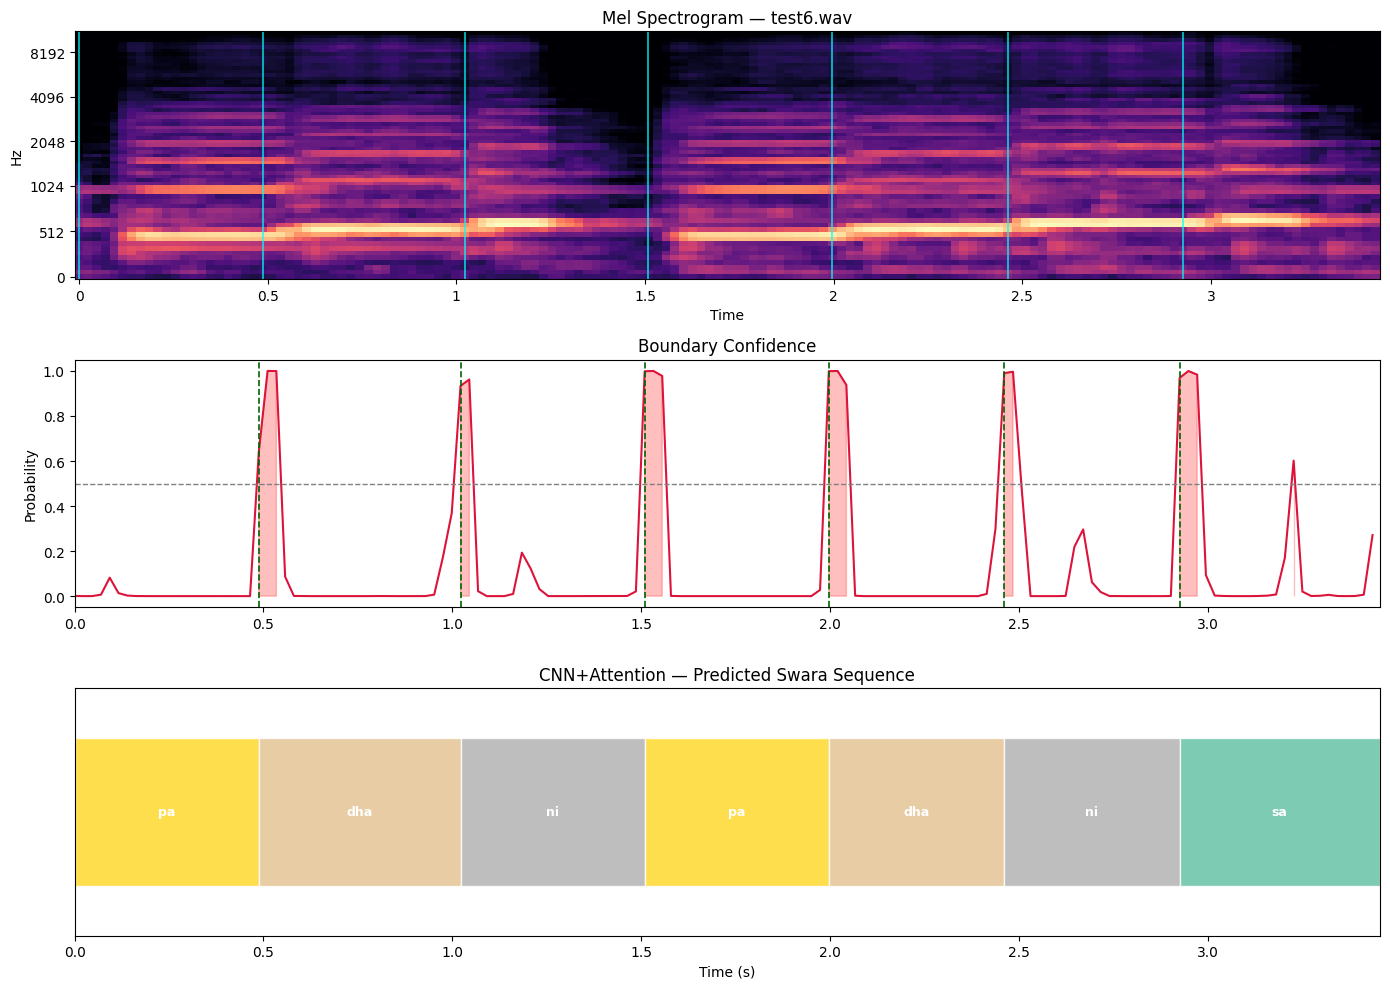


Processing: test7.wav
  [Edge] Dropping last boundary at 3.158s (only 0.242s from end)

Final boundaries (6): 0.488s, 0.929s, 1.509s, 1.927s, 2.392s, 2.902s
Classifying 7 segments...

  Seg 01  [0.000s – 0.488s]  CNN=dha  RFC=dha
  Seg 02  [0.488s – 0.929s]  CNN=ni  RFC=ni
  Seg 03  [0.929s – 1.509s]  CNN=sa  RFC=sa
  Seg 04  [1.509s – 1.927s]  CNN=dha  RFC=dha
  Seg 05  [1.927s – 2.392s]  CNN=ni  RFC=ni
  Seg 06  [2.392s – 2.902s]  CNN=sa  RFC=sa
  Seg 07  [2.902s – 3.400s]  CNN=sa  RFC=re

CNN+Attention sequence: dha → ni → sa → dha → ni → sa → sa
RFC sequence:           dha → ni → sa → dha → ni → sa → re


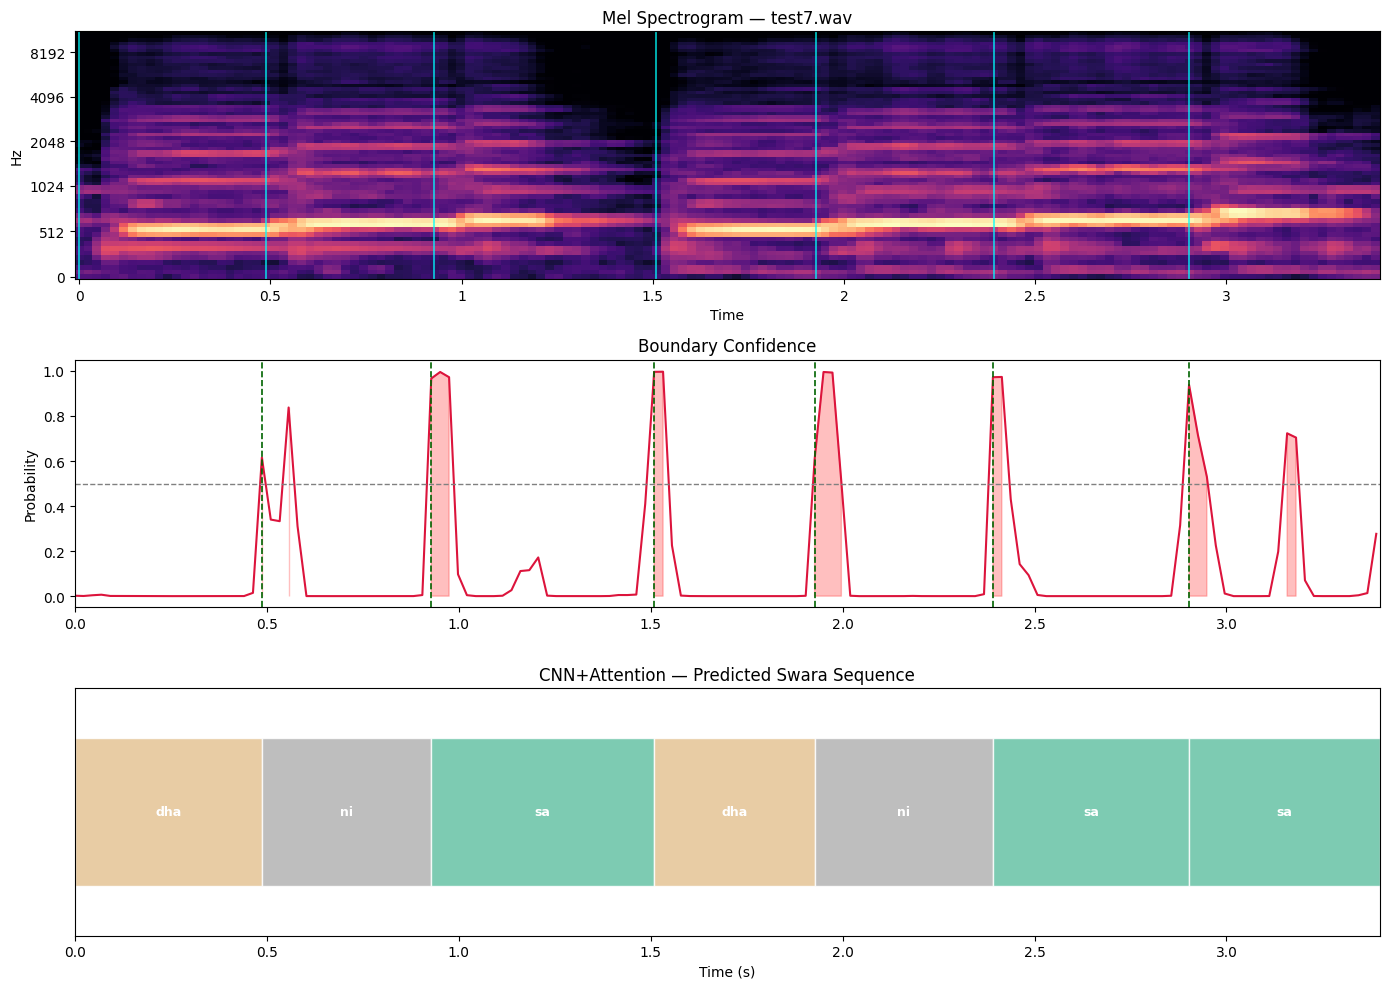


Processing: test8.wav
  [Edge] Dropping last boundary at 3.413s (only 0.015s from end)

Final boundaries (7): 0.116s, 0.488s, 0.952s, 1.556s, 1.927s, 2.392s, 2.902s
  [Edge] Dropping short segment [0.000–0.116]s (0.116s < 0.2s)
Classifying 7 segments...

  Seg 01  [0.116s – 0.488s]  CNN=ni  RFC=ni
  Seg 02  [0.488s – 0.952s]  CNN=sa  RFC=sa
  Seg 03  [0.952s – 1.556s]  CNN=sa  RFC=re
  Seg 04  [1.556s – 1.927s]  CNN=ni  RFC=ni
  Seg 05  [1.927s – 2.392s]  CNN=sa  RFC=sa
  Seg 06  [2.392s – 2.902s]  CNN=re  RFC=re
  Seg 07  [2.902s – 3.428s]  CNN=ni  RFC=ni

CNN+Attention sequence: ni → sa → sa → ni → sa → re → ni
RFC sequence:           ni → sa → re → ni → sa → re → ni


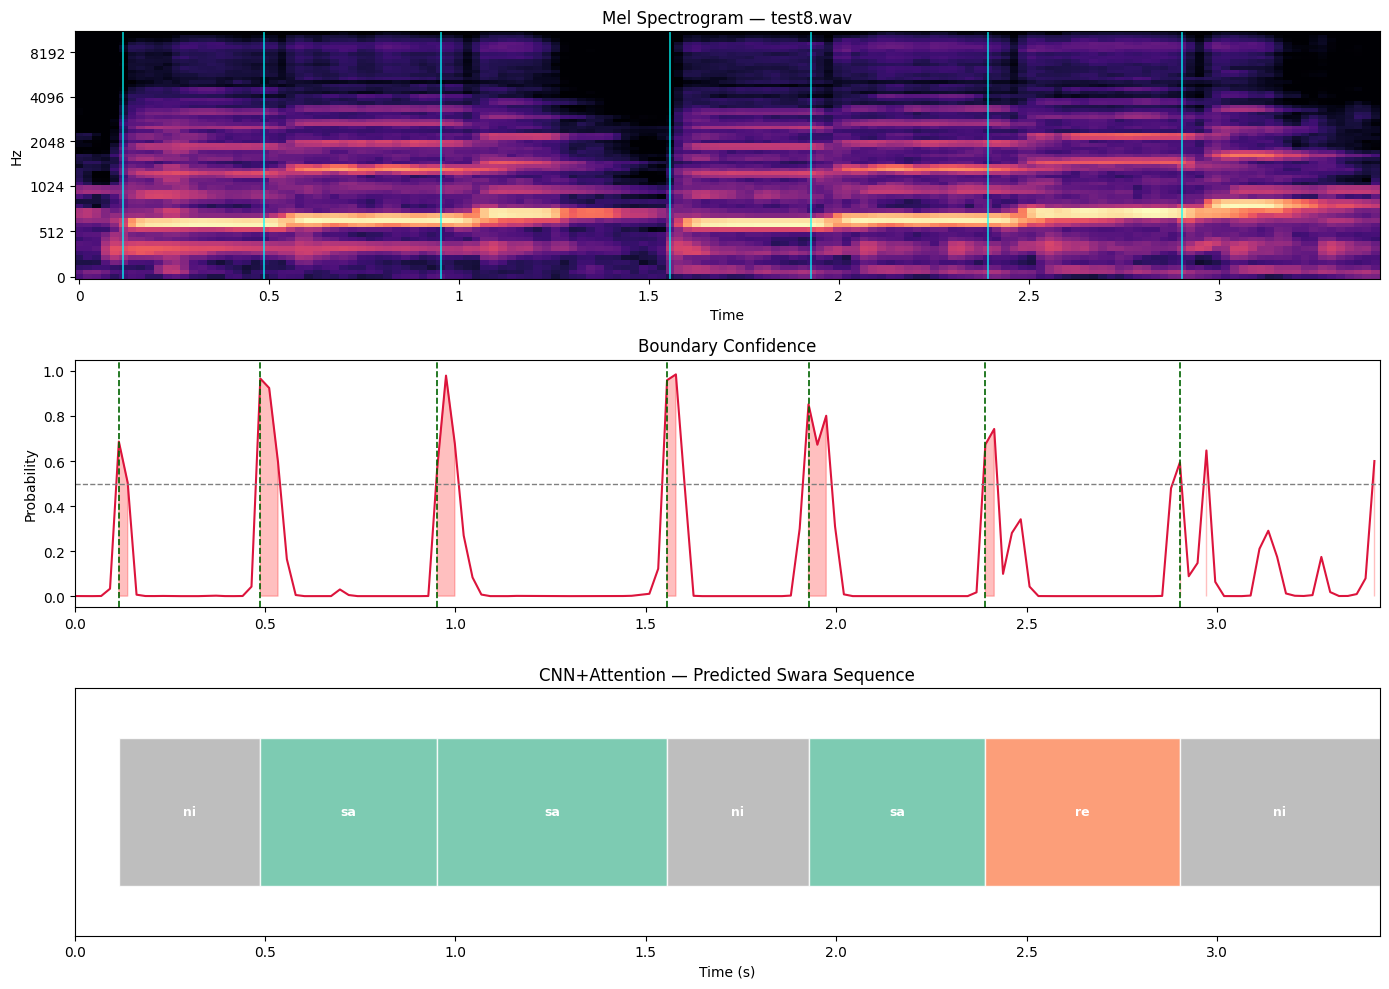


Processing: test9.wav
  [Edge] Dropping last boundary at 3.181s (only 0.205s from end)

Final boundaries (8): 0.093s, 0.534s, 1.068s, 1.254s, 1.556s, 1.950s, 2.415s, 2.972s
  [Edge] Dropping short segment [0.000–0.093]s (0.093s < 0.2s)
  [Edge] Dropping short segment [1.068–1.254]s (0.186s < 0.2s)
Classifying 7 segments...

  Seg 01  [0.093s – 0.534s]  CNN=ni  RFC=ni
  Seg 02  [0.534s – 1.068s]  CNN=sa  RFC=re
  Seg 03  [1.254s – 1.556s]  CNN=sa  RFC=sa
  Seg 04  [1.556s – 1.950s]  CNN=ni  RFC=ni
  Seg 05  [1.950s – 2.415s]  CNN=sa  RFC=ni
  Seg 06  [2.415s – 2.972s]  CNN=sa  RFC=sa
  Seg 07  [2.972s – 3.386s]  CNN=ni  RFC=ni

CNN+Attention sequence: ni → sa → sa → ni → sa → sa → ni
RFC sequence:           ni → re → sa → ni → ni → sa → ni


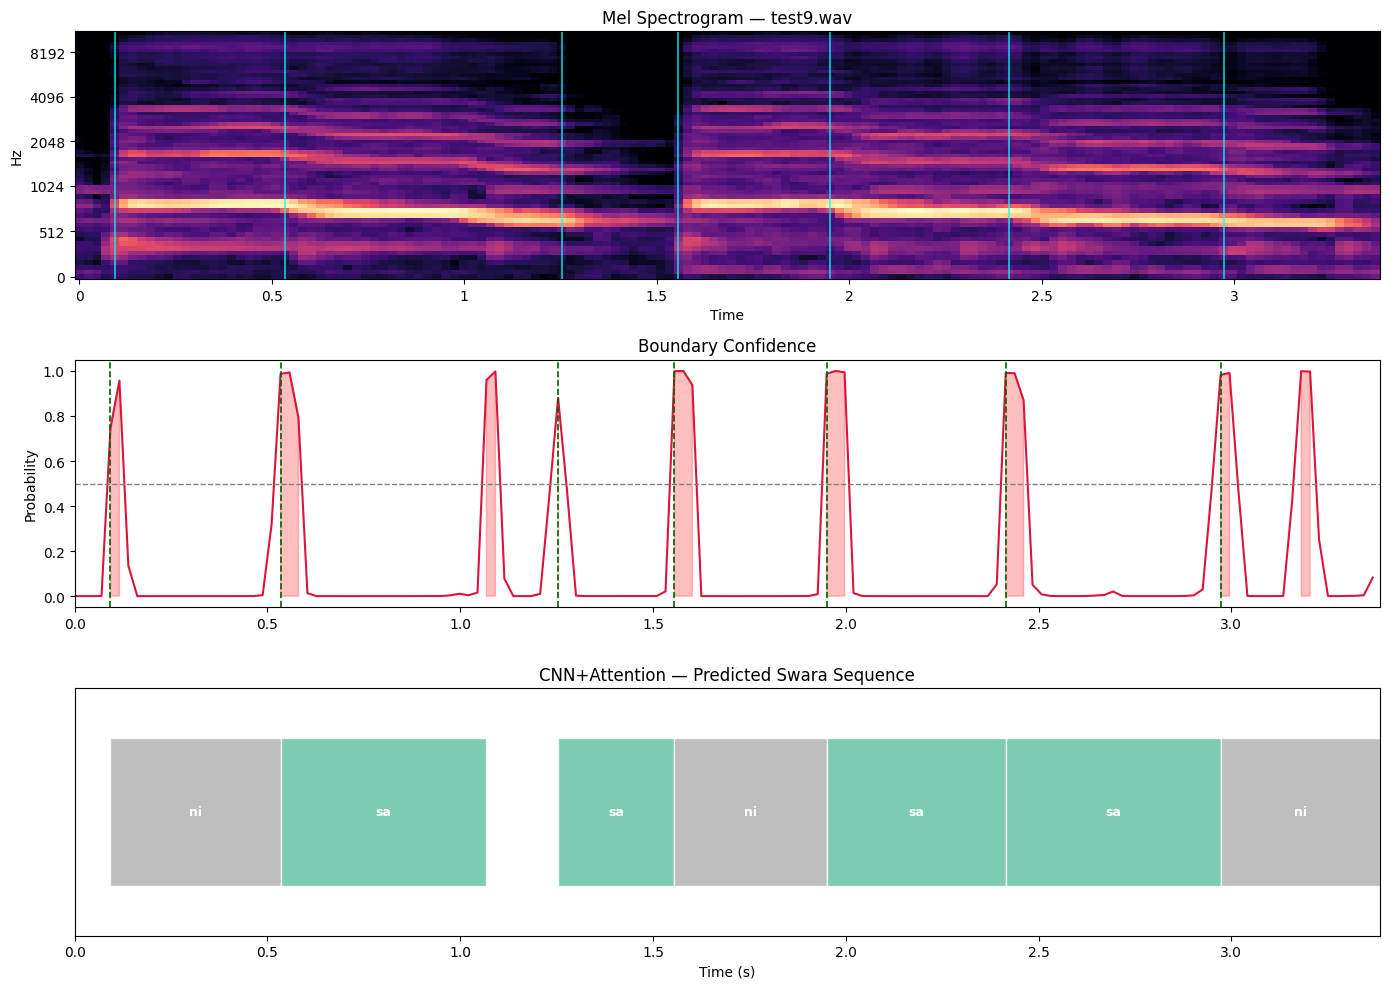


Processing: test10.wav
  [Edge] Dropping last boundary at 3.344s (only 0.146s from end)

Final boundaries (7): 0.163s, 0.534s, 1.022s, 1.625s, 1.997s, 2.485s, 2.949s
  [Edge] Dropping short segment [0.000–0.163]s (0.163s < 0.2s)
Classifying 7 segments...

  Seg 01  [0.163s – 0.534s]  CNN=re  RFC=ni
  Seg 02  [0.534s – 1.022s]  CNN=sa  RFC=sa
  Seg 03  [1.022s – 1.625s]  CNN=sa  RFC=ni
  Seg 04  [1.625s – 1.997s]  CNN=sa  RFC=ni
  Seg 05  [1.997s – 2.485s]  CNN=sa  RFC=sa
  Seg 06  [2.485s – 2.949s]  CNN=ni  RFC=ni
  Seg 07  [2.949s – 3.489s]  CNN=dha  RFC=dha

CNN+Attention sequence: re → sa → sa → sa → sa → ni → dha
RFC sequence:           ni → sa → ni → ni → sa → ni → dha


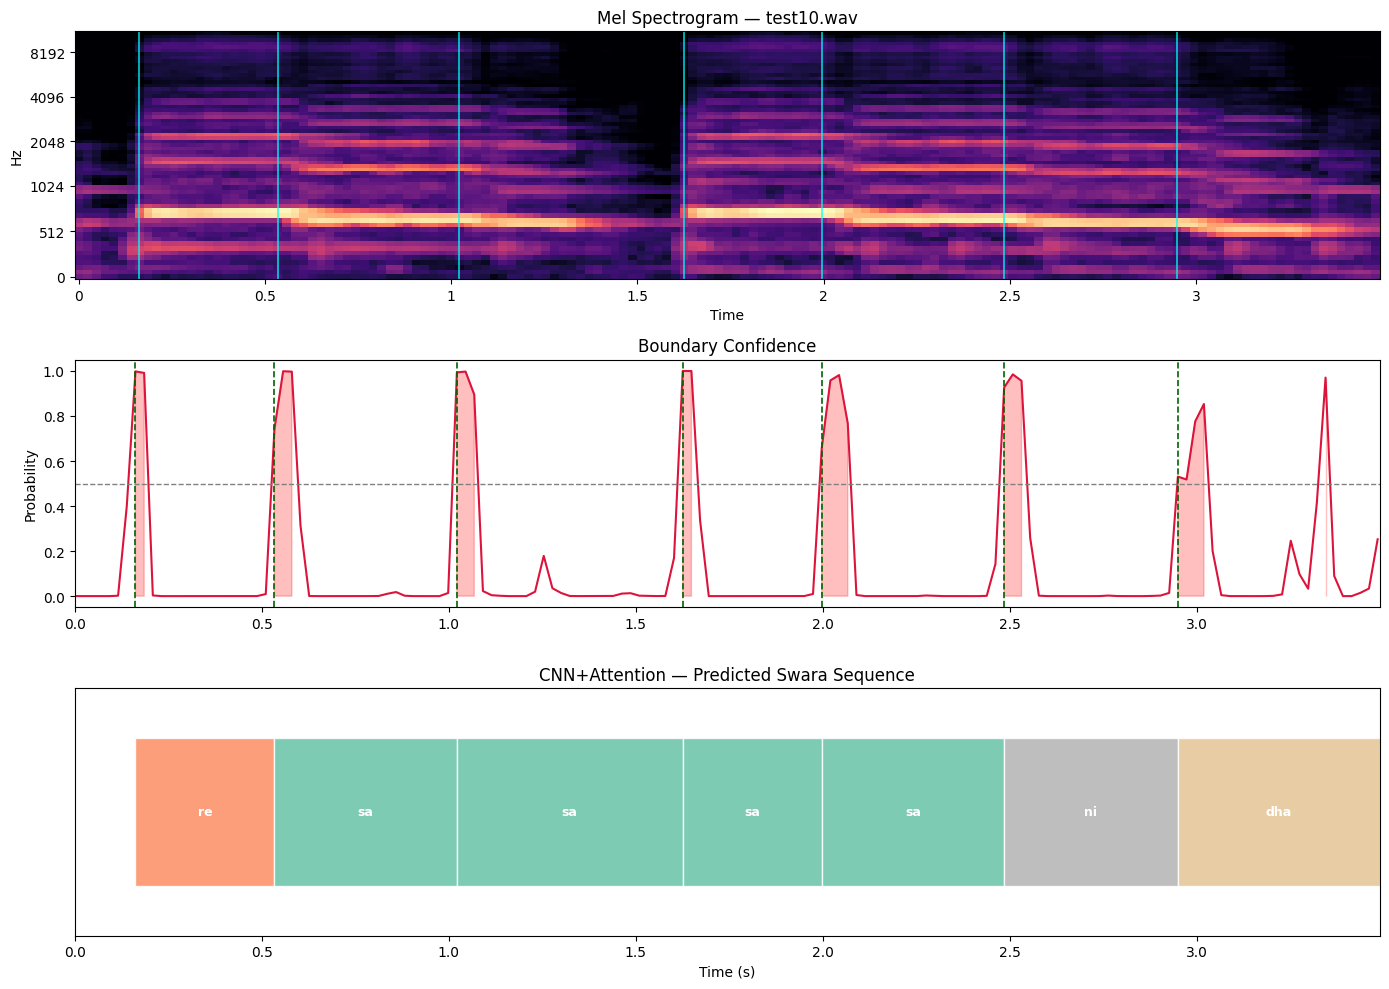


Processing: test11.wav

Final boundaries (6): 0.488s, 1.068s, 1.509s, 1.950s, 2.485s, 2.926s
Classifying 7 segments...

  Seg 01  [0.000s – 0.488s]  CNN=sa  RFC=sa
  Seg 02  [0.488s – 1.068s]  CNN=ni  RFC=ni
  Seg 03  [1.068s – 1.509s]  CNN=dha  RFC=dha
  Seg 04  [1.509s – 1.950s]  CNN=sa  RFC=sa
  Seg 05  [1.950s – 2.485s]  CNN=ni  RFC=ni
  Seg 06  [2.485s – 2.926s]  CNN=dha  RFC=dha
  Seg 07  [2.926s – 3.404s]  CNN=pa  RFC=pa

CNN+Attention sequence: sa → ni → dha → sa → ni → dha → pa
RFC sequence:           sa → ni → dha → sa → ni → dha → pa


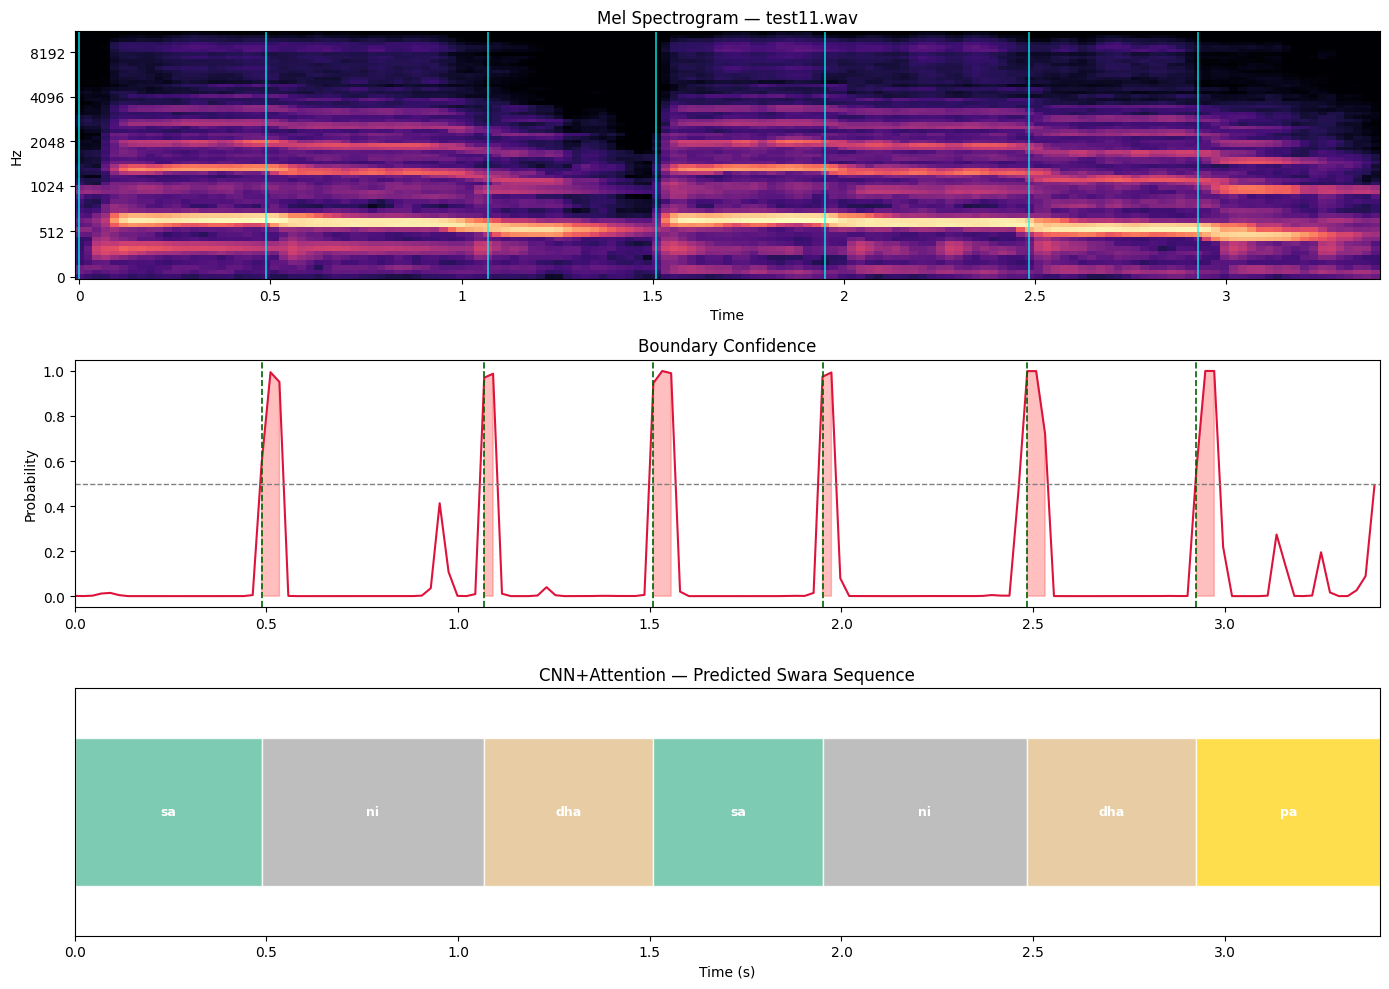


Processing: test12.wav
  [Edge] Dropping last boundary at 3.297s (only 0.051s from end)

Final boundaries (6): 0.534s, 1.022s, 1.533s, 1.997s, 2.485s, 2.995s
Classifying 7 segments...

  Seg 01  [0.000s – 0.534s]  CNN=ni  RFC=ni
  Seg 02  [0.534s – 1.022s]  CNN=dha  RFC=dha
  Seg 03  [1.022s – 1.533s]  CNN=pa  RFC=pa
  Seg 04  [1.533s – 1.997s]  CNN=ni  RFC=ni
  Seg 05  [1.997s – 2.485s]  CNN=dha  RFC=dha
  Seg 06  [2.485s – 2.995s]  CNN=pa  RFC=pa
  Seg 07  [2.995s – 3.348s]  CNN=ma  RFC=ma

CNN+Attention sequence: ni → dha → pa → ni → dha → pa → ma
RFC sequence:           ni → dha → pa → ni → dha → pa → ma


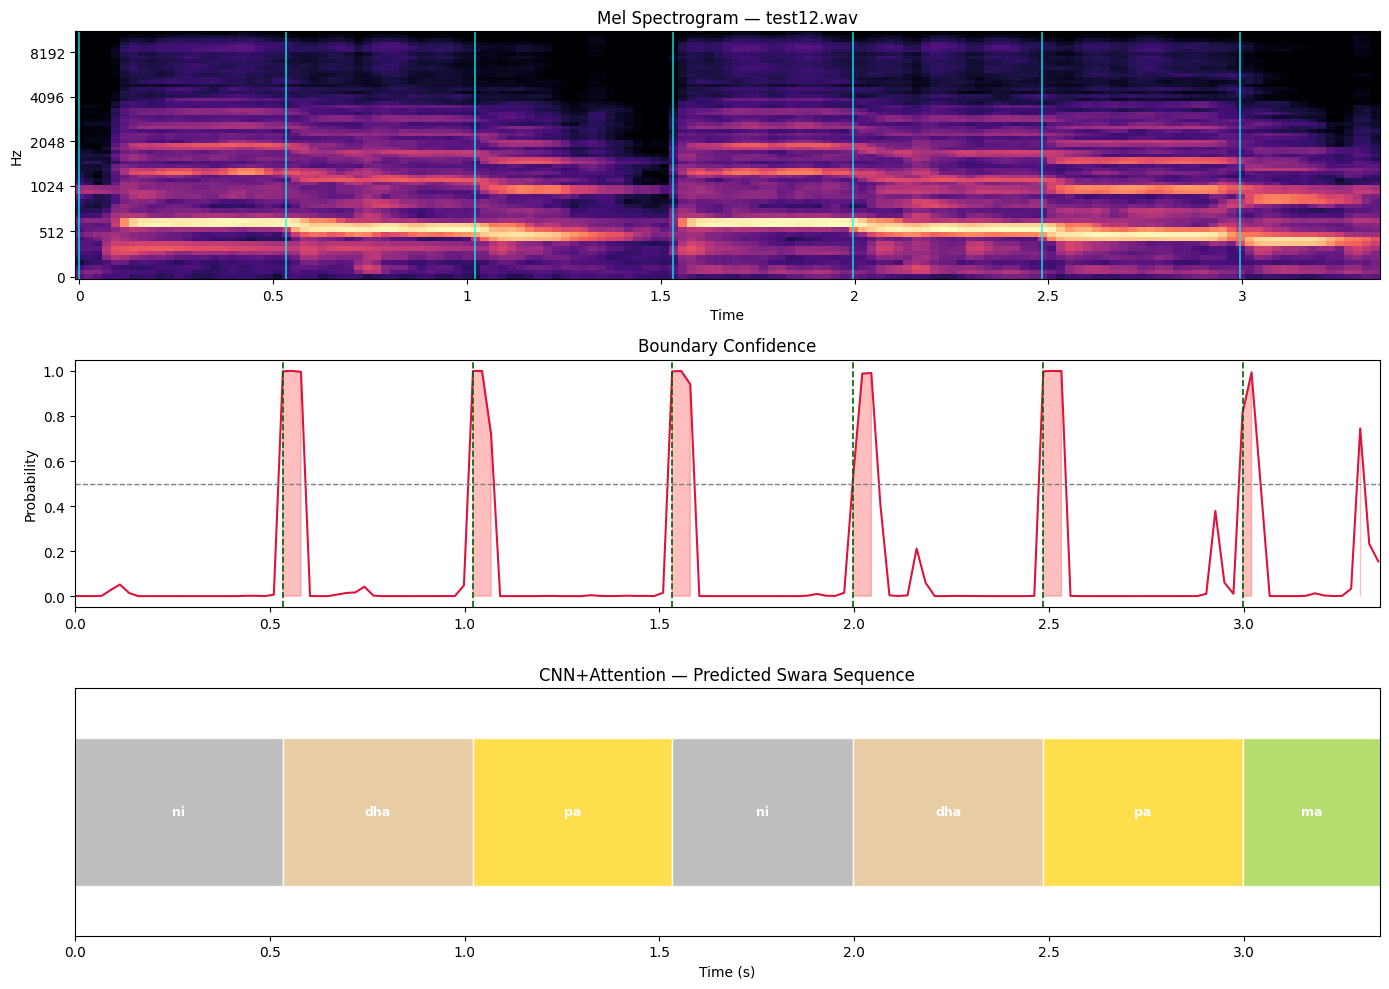


Processing: test13.wav

Final boundaries (8): 0.116s, 0.557s, 1.022s, 1.556s, 2.020s, 2.229s, 2.577s, 2.995s
  [Edge] Dropping short segment [0.000–0.116]s (0.116s < 0.2s)
Classifying 8 segments...

  Seg 01  [0.116s – 0.557s]  CNN=dha  RFC=dha
  Seg 02  [0.557s – 1.022s]  CNN=pa  RFC=pa
  Seg 03  [1.022s – 1.556s]  CNN=sa  RFC=ma
  Seg 04  [1.556s – 2.020s]  CNN=dha  RFC=dha
  Seg 05  [2.020s – 2.229s]  CNN=ma  RFC=ma
  Seg 06  [2.229s – 2.577s]  CNN=pa  RFC=pa
  Seg 07  [2.577s – 2.995s]  CNN=ma  RFC=ma
  Seg 08  [2.995s – 3.414s]  CNN=ga  RFC=ga

CNN+Attention sequence: dha → pa → sa → dha → ma → pa → ma → ga
RFC sequence:           dha → pa → ma → dha → ma → pa → ma → ga


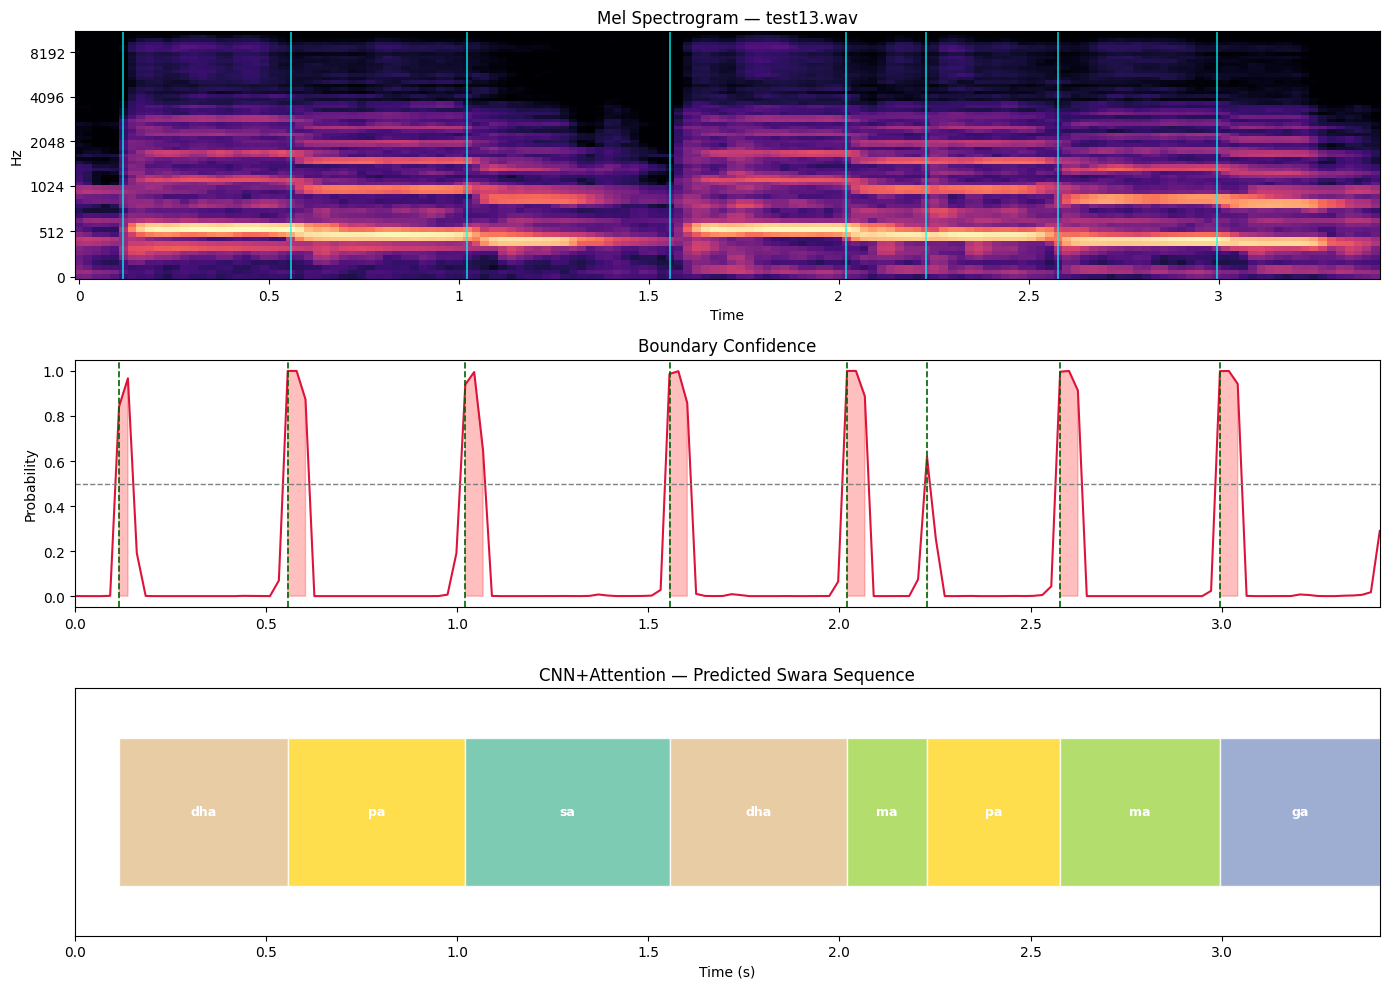


Processing: test14.wav
  [Edge] Dropping last boundary at 3.251s (only 0.173s from end)

Final boundaries (6): 0.557s, 0.998s, 1.509s, 1.997s, 2.485s, 2.949s
Classifying 7 segments...

  Seg 01  [0.000s – 0.557s]  CNN=pa  RFC=pa
  Seg 02  [0.557s – 0.998s]  CNN=ma  RFC=ma
  Seg 03  [0.998s – 1.509s]  CNN=ni  RFC=ma
  Seg 04  [1.509s – 1.997s]  CNN=pa  RFC=pa
  Seg 05  [1.997s – 2.485s]  CNN=ma  RFC=ma
  Seg 06  [2.485s – 2.949s]  CNN=ga  RFC=ma
  Seg 07  [2.949s – 3.423s]  CNN=sa  RFC=re

CNN+Attention sequence: pa → ma → ni → pa → ma → ga → sa
RFC sequence:           pa → ma → ma → pa → ma → ma → re


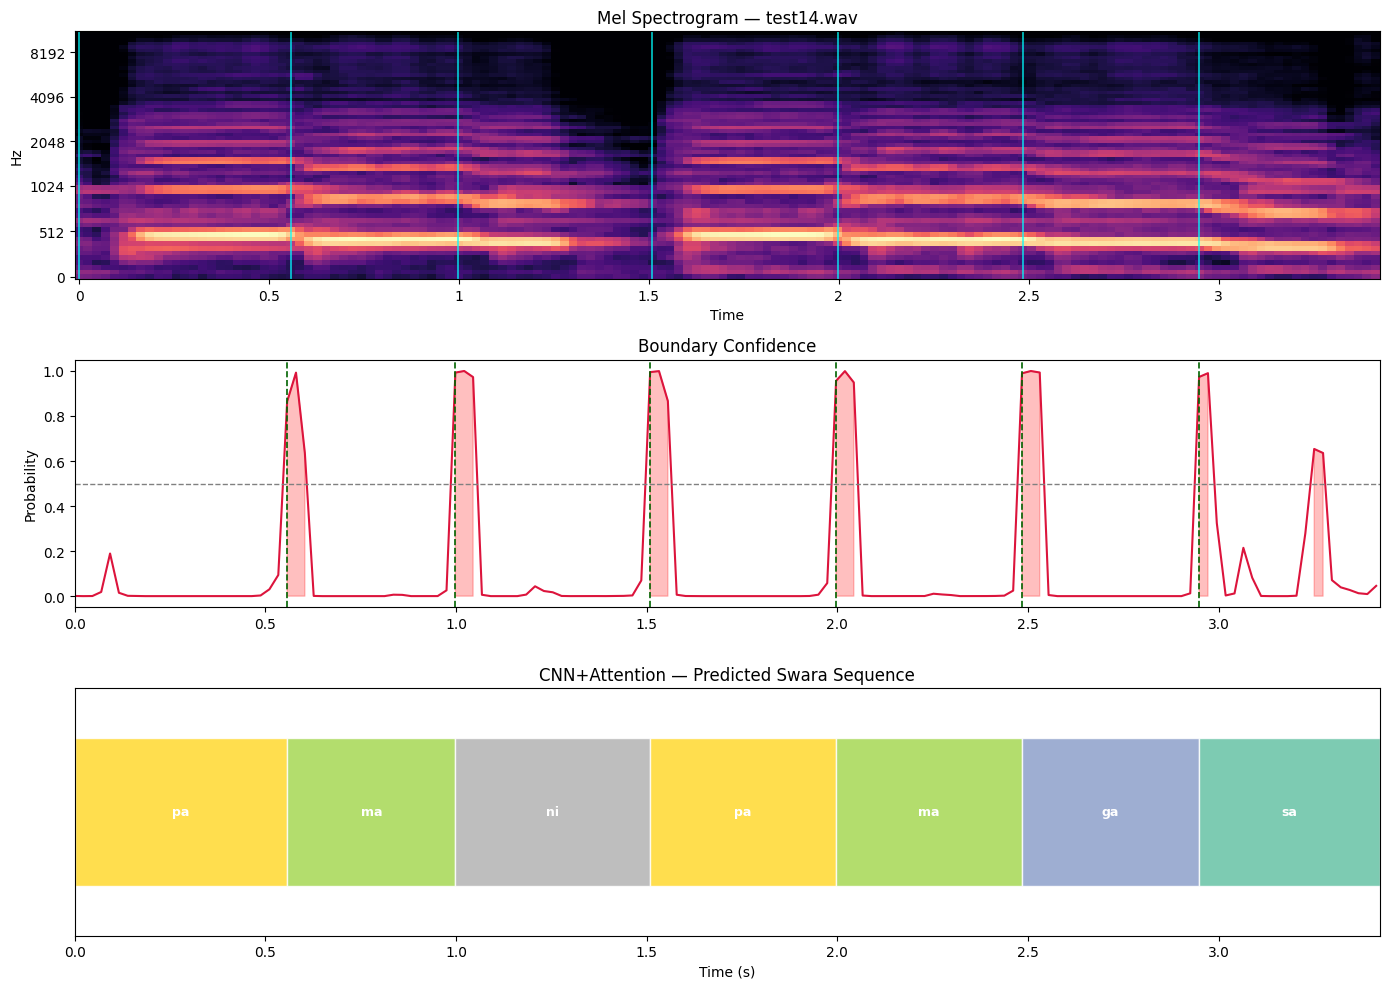


Processing: test15.wav
  [Edge] Dropping last boundary at 3.297s (only 0.117s from end)

Final boundaries (6): 0.511s, 1.045s, 1.533s, 1.950s, 2.461s, 2.949s
Classifying 7 segments...

  Seg 01  [0.000s – 0.511s]  CNN=ma  RFC=ma
  Seg 02  [0.511s – 1.045s]  CNN=ga  RFC=ga
  Seg 03  [1.045s – 1.533s]  CNN=sa  RFC=re
  Seg 04  [1.533s – 1.950s]  CNN=ma  RFC=ma
  Seg 05  [1.950s – 2.461s]  CNN=ga  RFC=ga
  Seg 06  [2.461s – 2.949s]  CNN=re  RFC=re
  Seg 07  [2.949s – 3.414s]  CNN=sa  RFC=sa

CNN+Attention sequence: ma → ga → sa → ma → ga → re → sa
RFC sequence:           ma → ga → re → ma → ga → re → sa


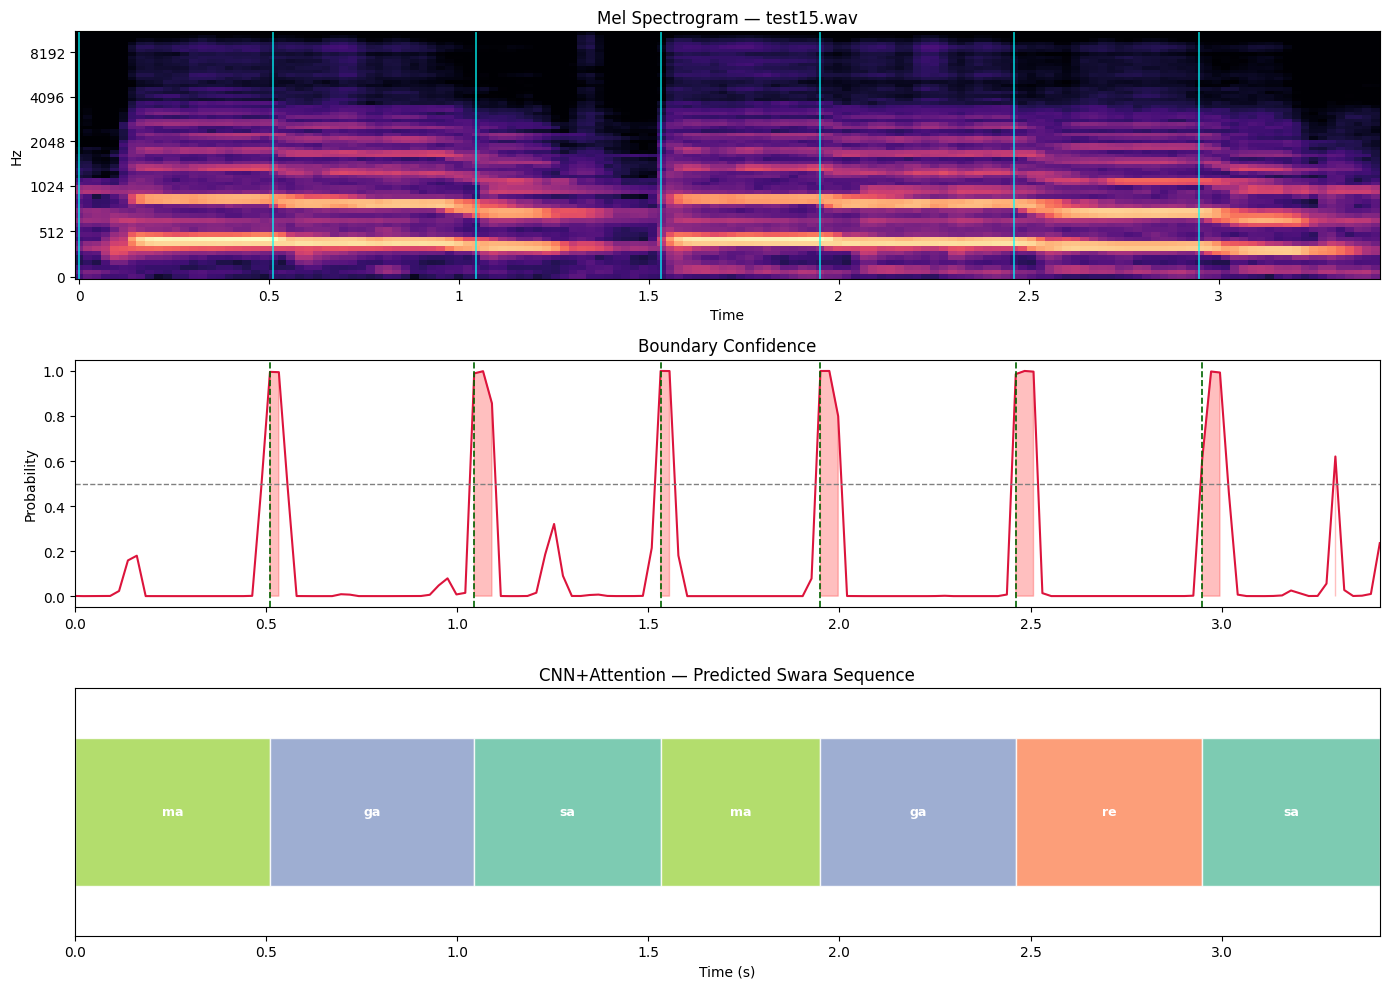


Processing: test16.wav
  [Edge] Dropping last boundary at 3.181s (only 0.205s from end)

Final boundaries (6): 0.488s, 0.975s, 1.509s, 1.950s, 2.438s, 2.972s
Classifying 7 segments...

  Seg 01  [0.000s – 0.488s]  CNN=sa  RFC=sa
  Seg 02  [0.488s – 0.975s]  CNN=re  RFC=re
  Seg 03  [0.975s – 1.509s]  CNN=ni  RFC=ga
  Seg 04  [1.509s – 1.950s]  CNN=sa  RFC=sa
  Seg 05  [1.950s – 2.438s]  CNN=re  RFC=re
  Seg 06  [2.438s – 2.972s]  CNN=ga  RFC=ga
  Seg 07  [2.972s – 3.386s]  CNN=ma  RFC=ma

CNN+Attention sequence: sa → re → ni → sa → re → ga → ma
RFC sequence:           sa → re → ga → sa → re → ga → ma


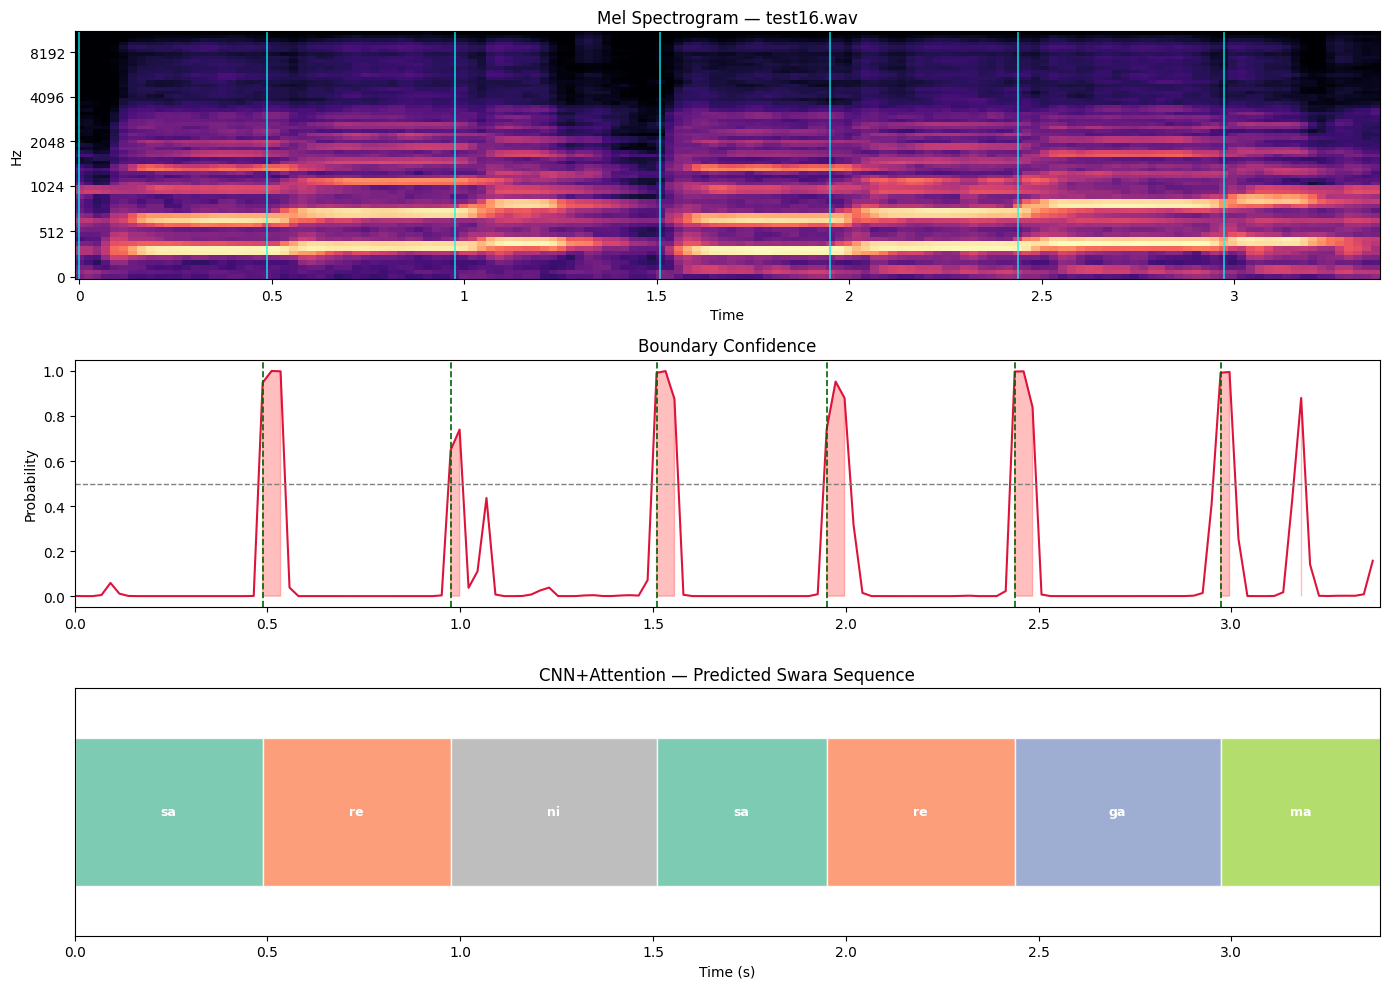


Processing: test17.wav
  [Edge] Dropping last boundary at 3.460s (only 0.015s from end)

Final boundaries (8): 0.116s, 0.534s, 1.022s, 1.556s, 1.997s, 2.485s, 2.995s, 3.228s
  [Edge] Dropping short segment [0.000–0.116]s (0.116s < 0.2s)
Classifying 8 segments...

  Seg 01  [0.116s – 0.534s]  CNN=re  RFC=re
  Seg 02  [0.534s – 1.022s]  CNN=ga  RFC=ga
  Seg 03  [1.022s – 1.556s]  CNN=ma  RFC=ma
  Seg 04  [1.556s – 1.997s]  CNN=re  RFC=re
  Seg 05  [1.997s – 2.485s]  CNN=ga  RFC=ga
  Seg 06  [2.485s – 2.995s]  CNN=ma  RFC=ma
  Seg 07  [2.995s – 3.228s]  CNN=ma  RFC=ma
  Seg 08  [3.228s – 3.475s]  CNN=ma  RFC=sa

CNN+Attention sequence: re → ga → ma → re → ga → ma → ma → ma
RFC sequence:           re → ga → ma → re → ga → ma → ma → sa


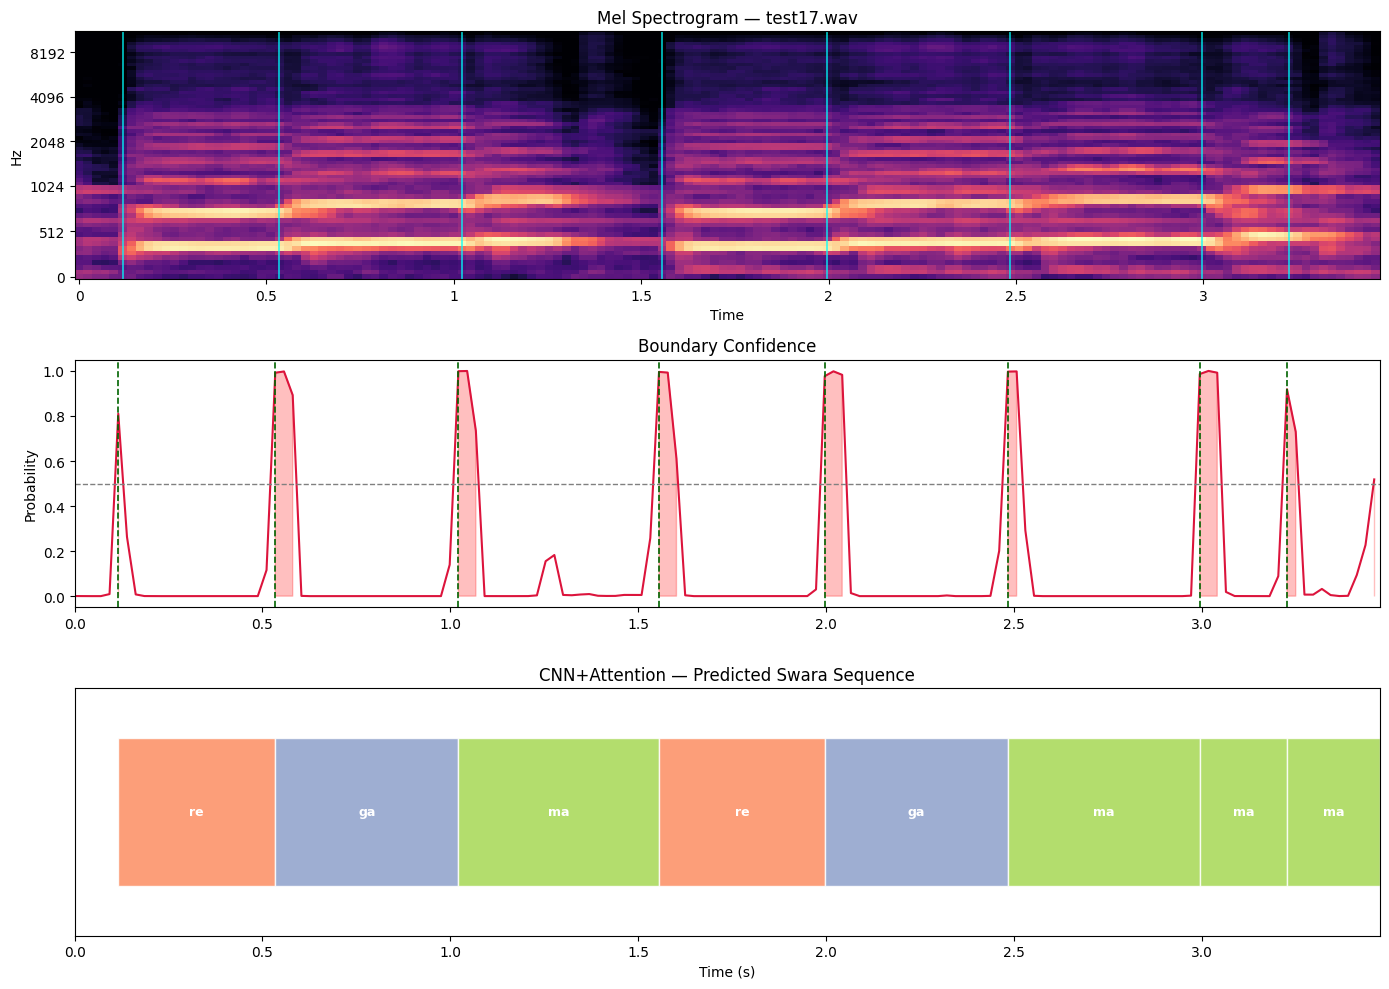


Processing: test18.wav
  [Edge] Dropping last boundary at 3.228s (only 0.243s from end)

Final boundaries (8): 0.163s, 0.557s, 1.045s, 1.556s, 2.020s, 2.508s, 2.763s, 3.019s
  [Edge] Dropping short segment [0.000–0.163]s (0.163s < 0.2s)
Classifying 8 segments...

  Seg 01  [0.163s – 0.557s]  CNN=ga  RFC=ga
  Seg 02  [0.557s – 1.045s]  CNN=ma  RFC=ma
  Seg 03  [1.045s – 1.556s]  CNN=pa  RFC=pa
  Seg 04  [1.556s – 2.020s]  CNN=ga  RFC=ga
  Seg 05  [2.020s – 2.508s]  CNN=ma  RFC=ma
  Seg 06  [2.508s – 2.763s]  CNN=ma  RFC=ma
  Seg 07  [2.763s – 3.019s]  CNN=ma  RFC=ga
  Seg 08  [3.019s – 3.470s]  CNN=dha  RFC=dha

CNN+Attention sequence: ga → ma → pa → ga → ma → ma → ma → dha
RFC sequence:           ga → ma → pa → ga → ma → ma → ga → dha


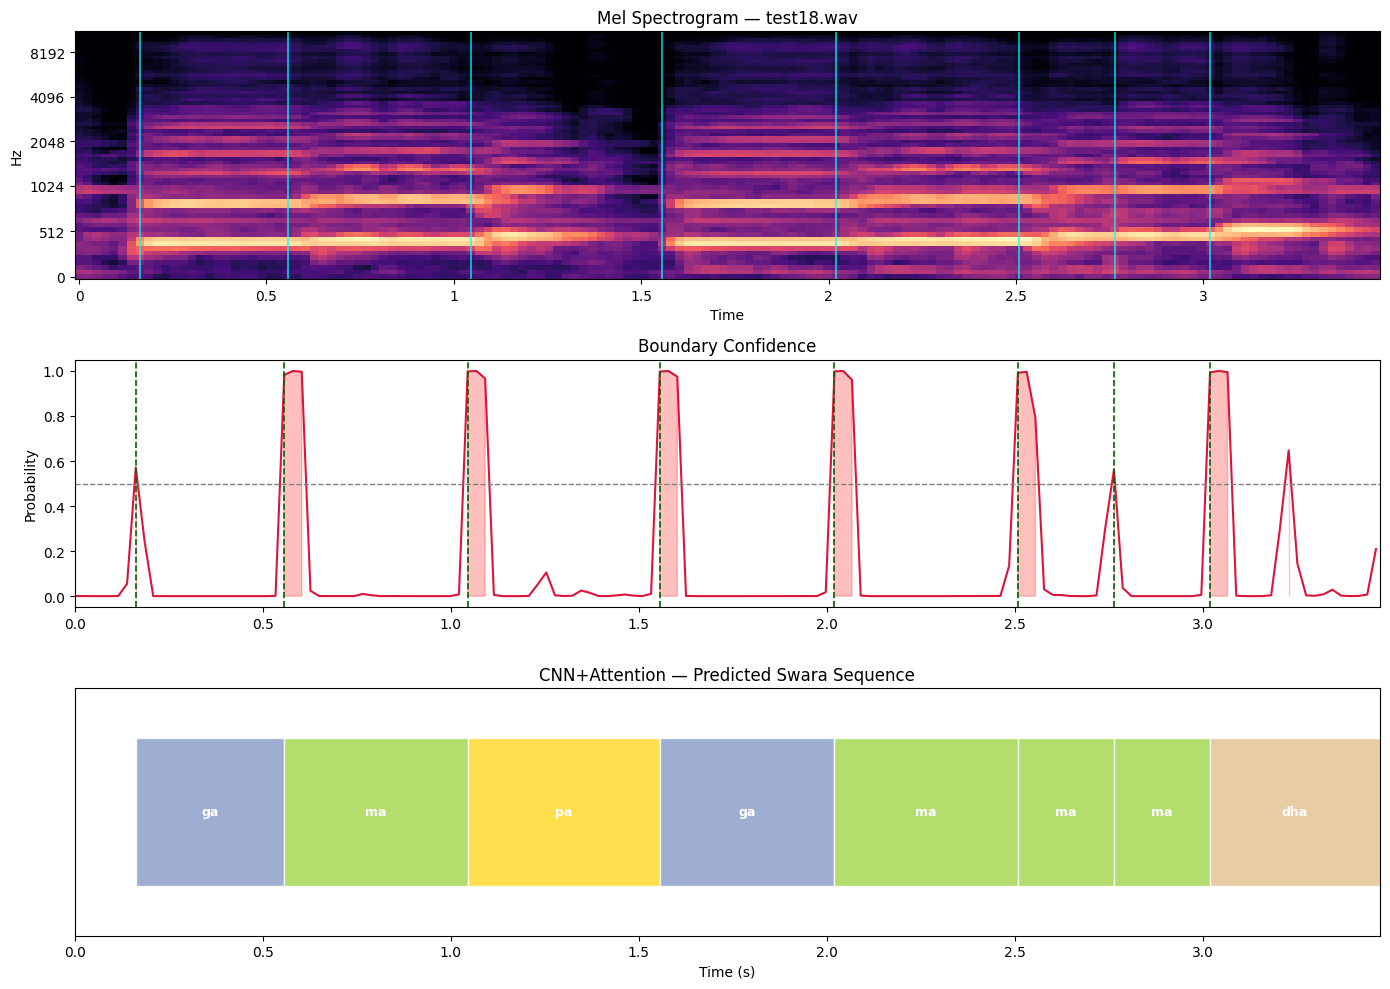


Processing: test19.wav

Final boundaries (6): 0.488s, 0.975s, 1.533s, 1.950s, 2.415s, 2.879s
Classifying 7 segments...

  Seg 01  [0.000s – 0.488s]  CNN=ma  RFC=ma
  Seg 02  [0.488s – 0.975s]  CNN=pa  RFC=pa
  Seg 03  [0.975s – 1.533s]  CNN=dha  RFC=dha
  Seg 04  [1.533s – 1.950s]  CNN=ma  RFC=ma
  Seg 05  [1.950s – 2.415s]  CNN=pa  RFC=pa
  Seg 06  [2.415s – 2.879s]  CNN=dha  RFC=dha
  Seg 07  [2.879s – 3.357s]  CNN=ni  RFC=ni

CNN+Attention sequence: ma → pa → dha → ma → pa → dha → ni
RFC sequence:           ma → pa → dha → ma → pa → dha → ni


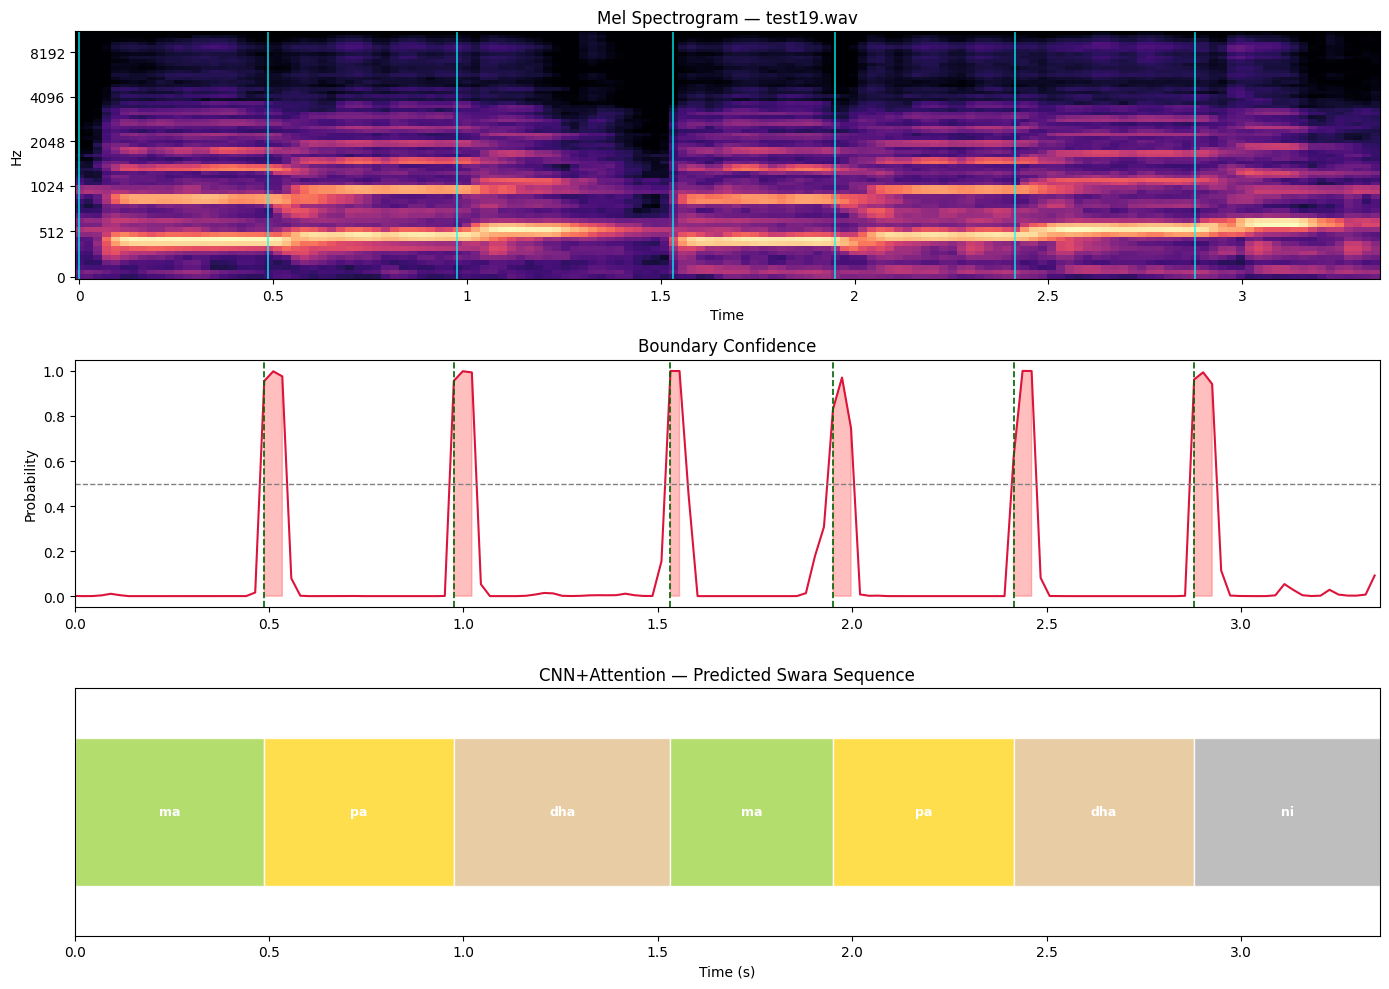


RESULTS SUMMARY
    clip_name                                              cnn_attention                                                       rfc
test1 (2).wav sa → re → sa → re → ni → sa → re → dha → re → ga → re → ga sa → re → sa → re → sa → sa → sa → sa → re → ga → re → ga
test2 (1).wav                           sa → re → ni → sa → re → ga → ma                          sa → re → ga → sa → re → ga → ma
test3 (1).wav                               re → ga → re → ga → ma → dha                              re → ga → dha → ga → ma → pa
test4 (1).wav                          ga → ma → pa → ga → ma → pa → dha                         ga → ma → pa → ma → ma → pa → dha
test5 (1).wav                         ma → pa → dha → ma → pa → dha → ni                        ma → pa → dha → ma → pa → dha → ni
    test6.wav                         pa → dha → ni → pa → dha → ni → sa                        pa → dha → ni → pa → dha → ni → sa
    test7.wav                         dha → ni → sa → dha → ni → s

In [17]:
# ==============================================================================
# CELL 9 — RUN (multiple files → results table)
# ==============================================================================

from google.colab import files as colab_files
import pandas as pd

print("Upload one or more test flute .wav files:")
uploaded = colab_files.upload()

rows = []
for audio_file in uploaded.keys():
    print(f"\n{'='*60}\nProcessing: {audio_file}\n{'='*60}")
    try:
        cnn_seq, rfc_seq, _ = run_pipeline(audio_file)
        rows.append({
            "clip_name":       audio_file,
            "cnn_attention":   " → ".join(cnn_seq),
            "rfc":             " → ".join(rfc_seq),
        })
    except Exception as e:
        print(f"  ERROR on {audio_file}: {e}")
        rows.append({
            "clip_name":     audio_file,
            "cnn_attention": "ERROR",
            "rfc":           "ERROR",
        })

results_df = pd.DataFrame(rows, columns=["clip_name", "cnn_attention", "rfc"])

print("\n" + "="*60)
print("RESULTS SUMMARY")
print("="*60)
print(results_df.to_string(index=False))

results_df.to_csv("swara_results.csv", index=False)
print("\nSaved → swara_results.csv")